# Лекция 6: Векторизация текста — от BoW до GloVe

**Что разберём:**

1. **Зачем тексту вектор.** Компьютер складывает числа, а не слова. Векторизация — это превращение текста в числа так, чтобы **геометрия** векторов отражала **смысл**.
2. **Bag of Words (BoW)** — простейшее представление: считаем слова. Дёшево и интерпретируемо, но теряет порядок и не понимает синонимию.
3. **TF-IDF** — BoW с весами важности: частые-везде слова (`the`, `of`, `is`) гасим, редкие-но-информативные — усиливаем.
4. **pPMI + SVD** — считаем, какие слова встречаются рядом, и превращаем матрицу совместной встречаемости в **плотные векторы слов** через факторизацию. Первый мостик к «настоящим» эмбеддингам.
5. **word2vec** — CBOW и Skip-gram. **Только теория:** архитектура, цель обучения, negative sampling и трюки; реализацию не пишем.
6. **FastText** — что делать с редкими и незнакомыми словами: добавляем **символьные n-граммы** (subword). Плюс быстрый классификатор текстов.
7. **GloVe** — глобальная лог-билинейная регрессия. Обучаем эмбеддинги **своей функцией потерь** на матрице совместной встречаемости.
8. **Сравнение** всех методов на реальной задаче: классифицируем предложения по темам (Buddhism, Israel, Portugal, …).

Но прежде чем считать слова, текст нужно **подготовить**. Поэтому в самом начале — **шаг 0: предобработка** (части 1.1–1.3): токенизация, а затем **стемминг и лемматизация** — сведение словоформ к основе. Это тот шаг, который определяет словарь, с которым дальше работают все методы.

**Идея лекции.** Все методы отвечают на один вопрос: *как из текста сделать вектор*. Разница — в том, **что считать «единицей смысла»**:

- BoW / TF-IDF: единица — **слово как индекс**, вектор — счётчики по словам (разреженный, огромной размерности).
- pPMI+SVD, word2vec, FastText, GloVe: единица — **слово как вектор**, который сжимает *контекст*, где слово встречается (плотный, 50–300 чисел).

> Всё, кроме word2vec, реализуем «с нуля» на NumPy и чистом PyTorch: никаких `gensim`, `spacy` и готовых эмбеддингов. Так видно, что внутри.

**Обозначения (сквозные):**

| Символ | Смысл |
|---|---|
| $\mathcal{V}$ | словарь, $V = |\mathcal{V}|$ — его размер |
| $w$ | слово (токен) |
| $c$ | контекст слова (сосед в окне) |
| $x \in \mathbb{R}^{V}$ | вектор документа в BoW-пространстве |
| $\mathrm{tf}(t, d)$ | число вхождений термина $t$ в документ $d$ |
| $\mathrm{idf}(t)$ | обратная документная частота термина $t$ |
| $\mathrm{PMI}(w, c)$ | pointwise mutual information между словом и контекстом |
| $E \in \mathbb{R}^{V \times d}$ | матрица эмбеддингов; строка $E_w$ — вектор слова $w$ |
| $d$ | размерность эмбеддинга (обычно 50–300) |


## Карта лекции

```text
                       ТЕКСТ  →  ЧИСЛА
                            │
        ┌───────────────────┴────────────────────┐
        │                                        │
   «мешок слов»                            «слово = вектор»
   (разреженно, V мерностей)               (плотно, d мерностей)
        │                                        │
   ┌────┴────┐              ┌──────────┬──────────┼──────────┐
   │         │              │          │          │          │
  BoW   TF-IDF          pPMI+SVD   word2vec   FastText    GloVe
                          │        (теория)      │          │
                     счёт + SVD              subword    глобальная
                     (LSA, 1990)             + негат.   регрессия
                                                 сэмпл
        │                                        │
        └──────────────► СРАВНЕНИЕ ◄─────────────┘
                 задача классификации текстов
```

Сначала — слова и формулы, затем — код, в конце — честное сравнение на одной задаче.

## 0. Импорты, seed, устройство

Пишем **device-agnostic** код (CUDA/MPS/CPU) и фиксируем seed. Эмбеддинги обучаем на PyTorch, счётные методы — на NumPy/SciPy.

In [1]:
import os, re, json, time, random, collections
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from nltk.tokenize import sent_tokenize

# ---------- воспроизводимость ----------
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available()
                      else 'mps' if torch.backends.mps.is_available()
                      else 'cpu')

plt.rcParams['figure.dpi'] = 110
plt.rcParams['figure.figsize'] = (8, 4)

print('numpy', np.__version__, '| torch', torch.__version__, '| device:', device)

numpy 1.21.2 | torch 2.2.0.dev20230914+cu121 | device: cuda


## 1. Данные

В корне репозитория лежит `squad-v2.0.json` — датасет **SQuAD v2.0** (Stanford Question Answering). Нам он интересен не как задача QA, а как большой корпус английского текста: 442 статьи Википедии, ~19 000 абзацев, ~94 000 предложений.

Если файла нет, его можно скачать с официального сайта SQuAD:

* обучающая часть (~42 МБ): <https://rajpurkar.github.io/SQuAD-explorer/dataset/train-v2.0.json>
* отложенная часть (~4 МБ): <https://rajpurkar.github.io/SQuAD-explorer/dataset/dev-v2.0.json>

Мы используем `train-v2.0.json` и называем его `squad-v2.0.json`. Из терминала:

```bash
curl -L -o squad-v2.0.json https://rajpurkar.github.io/SQuAD-explorer/dataset/train-v2.0.json
```

Почему именно он:

* **одно предложение = один документ** — удобно для BoW/TF-IDF и для классификации;
* текст реальный, «грязный» (числа, аббревиатуры, скобки) — в отличие от игрушечных примеров;
* статьи имеют **тему** (`title`), а значит есть готовая разметка для задачи классификации.

Загрузим статьи, соберём предложения и посмотрим на объёмы.

In [2]:
import urllib.request

SQUAD_URL = 'https://rajpurkar.github.io/SQuAD-explorer/dataset/train-v2.0.json'

def find_squad():
    '''Ищем датасет рядом с ноутбуком; если нет — скачиваем официальный train-v2.0.'''
    candidates = ['squad-v2.0.json', '../squad-v2.0.json', '../../squad-v2.0.json']
    for c in candidates:
        if os.path.exists(c):
            return c
    print('squad-v2.0.json не найден, скачиваю с', SQUAD_URL)
    local = 'squad-v2.0.json'
    urllib.request.urlretrieve(SQUAD_URL, local)
    return local

t_start = time.time()
squad = json.load(open(find_squad()))['data']

# (тема статьи, абзац)
paragraphs = [(article['title'], p['context'])
              for article in squad for p in article['paragraphs']]

# все предложения корпуса
all_sentences = [s for _, ctx in paragraphs for s in sent_tokenize(ctx)]

print(f'статей:        {len(squad)}')
print(f'абзацев:       {len(paragraphs)}')
print(f'предложений:   {len(all_sentences)}')
print(f'символов:      {sum(len(p) for _, p in paragraphs):,}')
print(f'время загрузки: {time.time() - t_start:.1f} c')
print()
print('Пример предложения:')
print(' ', all_sentences[0][:180], '...')

статей:        442
абзацев:       19035
предложений:   94224
символов:      14,001,154
время загрузки: 3.2 c

Пример предложения:
  Beyoncé Giselle Knowles-Carter (/biːˈjɒnseɪ/ bee-YON-say) (born September 4, 1981) is an American singer, songwriter, record producer and actress. ...


### 1.1. Токенизация

Прежде чем считать слова, текст надо разбить на **токены**. Берём простой и предсказуемый регексп: последовательности латинских букв, цифр и апострофа. Всё остальное (пунктуация, скобки, дефисы) — разделители.

Это ровно тот шаг, где теряется часть информации (например, что `don't` — это отрицание), но для лекции важнее прозрачность: одна функция — одно правило.

Введём **токенизаторы** двух уровней:

* `tokenize(s)` — слова (то, что дальше идёт в BoW и в эмбеддинги);
* `tokenize_sent(s)` — оставляем `'<num>'` вместо чисел (для аккуратных примеров).

Будем дополнительно заменять на плейсхолдеры очень редкие-специфичные штуки вроде чисел, чтобы словарь не засорялся.

In [3]:
TOKEN_RE = re.compile(r"[a-z0-9']+")

def tokenize(text):
    '''Слова в нижнем регистре: буквы/цифры/апостроф.'''
    return TOKEN_RE.findall(text.lower())

def sent_tokens(text):
    '''Токены с заменой чисел на <num> — полезно для аккуратных примеров.'''
    return [('<num>' if t.isdigit() else t) for t in tokenize(text)]

example = "In 1969 the Apollo 11 landed on the Moon's surface!"
print('текст: ', example)
print('слова: ', tokenize(example))
print('с <num>:', sent_tokens(example))

текст:  In 1969 the Apollo 11 landed on the Moon's surface!
слова:  ['in', '1969', 'the', 'apollo', '11', 'landed', 'on', 'the', "moon's", 'surface']
с <num>: ['in', '<num>', 'the', 'apollo', '<num>', 'landed', 'on', 'the', "moon's", 'surface']


### 1.2. Первый взгляд на словарь

Посчитаем частоты слов на небольшой части корпуса. Это даст представление о **длинном хвосте**: несколько частотных слов (`the`, `of`, `and`) и десятки тысяч редких.

In [4]:
# частоты на выборке корпуса
sample_tokens = [tokenize(s) for s in all_sentences[:20000]]
freq = collections.Counter()
for toks in sample_tokens:
    freq.update(toks)

print(f'уникальных токенов на выборке: {len(freq):,}')
print()
print('Топ-15 частых слов:')
for w, c in freq.most_common(15):
    print(f'  {w:12s} {c:>8,}')
print()
print('Слова с частотой 1 (singletons):', sum(1 for c in freq.values() if c == 1))
print('Доля словаря с частотой <= 5:   {:.1%}'.format(
    sum(1 for c in freq.values() if c <= 5) / len(freq)))

уникальных токенов на выборке: 33,576

Топ-15 частых слов:
  the            36,373
  of             17,755
  and            14,431
  in             13,149
  to             10,128
  a               8,677
  as              4,634
  is              4,249
  was             3,963
  for             3,611
  by              3,503
  that            3,345
  with            3,154
  on              3,120
  from            2,552

Слова с частотой 1 (singletons): 15144
Доля словаря с частотой <= 5:   76.8%


### 1.3. Стемминг и лемматизация

До сих пор мы приводили слово к нижнему регистру — и всё. Но на самом деле
`studies`, `studied` и `studying` — это **одно и то же слово** в разных формах,
а в словаре они до сих пор сидели тремя разными столбцами. Английский ещё так себе:
`сдал` / `сдала` / `сдали` тут честно разные слова. А вот в русском каждая форма —
отдельный токен, и словарь раздувается в разы: `кот`, `кота`, `коту`, `коты`,
`котами`…

Отсюда идея: **схлопнуть словоформы к их основе**, чтобы `run`, `runs`, `running`,
`ran` стали одним признаком. Тогда модель увидит смысл, а не грамматику, и словарь
уменьшится. Делают это двумя способами — **стеммингом** и **лемматизацией**.

#### Стемминг

Стеммер — это грубый **набор правил обрезки суффиксов**. Он гоняет слово по
последовательности шагов и отрезает окончания. Самый известный (и встроенный в
NLTK) — **алгоритм Портера** (Porter, 1980):

```text
каждое слово = основа + суффикс;  отрезаем суффикс по правилам

"studies"   ──шаг 1──►  "studi"      (ies → i)
"running"   ──шаг 1──►  "run"        (ing → ε)
"happiness" ──шаг 3──►  "happi"      (ness → ε)
```

* **Плюсы:** молниеносно, не нужно никаких словарей, легко написать самому.
* **Минусы:** результат не обязан быть настоящим словом (`studi`, `happi`, `argu`),
  и правила грубо ошибаются: `university → univers`, `was → wa`.

Посмотрим алгоритм Портера в действии.

In [ ]:
from nltk.stem import PorterStemmer, SnowballStemmer

porter = PorterStemmer()
snowball = SnowballStemmer('english')          # улучшенный Портер («Porter2»)

words_demo = ['run', 'runs', 'running', 'ran', 'runner',
              'study', 'studies', 'studied', 'studying',
              'university', 'happy', 'happiness', 'was', 'argue', 'arguing']

print(f'{"слово":12s} {"Porter":12s} {"Snowball":12s}')
print('-' * 38)
for w in words_demo:
    print(f'{w:12s} {porter.stem(w):12s} {snowball.stem(w):12s}')

Обратите внимание на две вещи:

1. **Формы одного слова слились:** `run`, `runs`, `running` → `run`.
   Именно этого мы и хотели.
2. **Стеммер не думает о смысле.** `university` → `univers`, `happiness` → `happi`,
   `was` → `wa`. Это не ошибка библиотеки — это свойство грубых правил: чтобы
   работать быстро и без словаря, приходится жертвовать правильностью формы.

Snowball — это формализованный «Портер 2», его обычно берут вместо классического
Портера. Правила Snowball для английского можно [посмотреть глазами](https://snowballstem.org/algorithms/english/stemmer.html):
набор условий вроде «отрезать `ing`, если основа длиннее 2 букв».

#### Лемматизация

Лемматизатор делает то же самое, но **по-умному**: не режет слово, а ищет в словаре
**лемму** — начальную (словарную) форму, ту, что стоит в заголовке статьи словаря:
`mice → mouse`, `went → go`, `better → good`, `was → be`.

Работает это через **морфологический анализ**: нужно знать часть речи и разобрать
форму. В NLTK есть `WordNetLemmatizer`, который опирается на лексическую базу
**WordNet** (электронный словарь английского от Princeton, 1995). Важная тонкость:
лемматизатору **надо подсказать часть речи** (`pos`), иначе он считает слово
существительным:

* с `pos='v'`: `running → run`, `was → be`;
* без подсказки (`pos='n'` по умолчанию): `running → running` (как существительное
  «бег» формы не имеет).

Поэтому лемматизацию обычно запускают **после POS-теггера** — модуля, который
размечает каждое слово его грамматической категорией (NN — существительное,
VB — глагол, JJ — прилагательное…). Напишем маленький теггер на NLTK
(`averaged_perceptron_tagger`) и лемматизатор, который умеет пользоваться этой
разметкой.

In [ ]:
import nltk
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag
from nltk.corpus import wordnet

for pkg in ['wordnet', 'omw-1.4', 'averaged_perceptron_tagger']:
    nltk.download(pkg, quiet=True)

# маппинг тега Penn Treebank (NN, VBZ, JJ, RB...) -> тег WordNet (n, v, a, r)
def penn_to_wordnet(tag):
    '''Какую часть речи ждёт WordNetLemmatizer.'''
    if tag.startswith('J'):
        return wordnet.ADJ      # 'a'
    if tag.startswith('V'):
        return wordnet.VERB     # 'v'
    if tag.startswith('N'):
        return wordnet.NOUN     # 'n'
    if tag.startswith('R'):
        return wordnet.ADV      # 'r'
    return wordnet.NOUN

wnl = WordNetLemmatizer()

def lemmatize_pos(text):
    '''Леммы всех слов текста: POS-теггер + лемматизатор.'''
    toks = tokenize(text)
    return [wnl.lemmatize(t, penn_to_wordnet(tag)) for t, tag in pos_tag(toks)]

words_demo = ['was', 'were', 'running', 'better', 'mice', 'studies',
              'children', 'went', 'quickly']

print(f'{"слово":10s} {"POS":5s} {"Porter":10s} {"Лемма":10s}')
print('-' * 40)
for w, tag in pos_tag(words_demo):
    print(f'{w:10s} {tag:5s} {porter.stem(w):10s} {wnl.lemmatize(w, penn_to_wordnet(tag)):10s}')

Вуаля: леммы — настоящие слова. `was → be`, `mice → mouse`, `better → good`
(прилагательное!), `children → child`. Стеммер бы дал `wa`, `mice` → `mice`
(он не знает про неправильные формы), `better → better`.

**Цена.** Лемматизация дороже: нужен словарь (WordNet — сотни мегабайт),
POS-теггер и собственно морфологический разбор. Стемминг — это чистая
арифметика над строками. Поэтому в больших продакшн-пайплайнах, где важна скорость,
часто живёт именно стеммер (или вообще никакой нормализации).

#### Сводная таблица

| | **Стемминг** | **Лемматизация** |
|---|---|---|
| Что делает | режет суффиксы по правилам | ищет словарную форму |
| Нужен словарь | нет | да (WordNet и т.п.) |
| Часть речи | не нужна | нужна для качества |
| Скорость | очень быстро | медленно |
| Результат | не всегда настоящее слово | всегда настоящая лемма |
| `was` | `wa` | `be` |
| `mice` | `mice` | `mouse` |
| `better` | `better` | `good` |
| Русский | `SnowballStemmer('russian')` | `pymorphy2` / `spaCy` |

В лекции мы принципиально не тянем `spaCy`/`pymorphy2` и работаем на NLTK —
но помните, что в реальных проектах для русского берут `pymorphy2`.

#### Что это даёт на нашем корпусе

Теперь измерим эффект на SQuAD. Сравним три представления:

* **raw** — как в 1.2 (только нижний регистр);
* **stem** — после `SnowballStemmer`;
* **lemm** — после POS-теггинга + `WordNetLemmatizer`.

Считаем размер словаря ($V$), сколько форм одного слова «схлопнулось» и как
изменилась разреженная BoW-матрица.

In [ ]:
import time

# небольшой, но показательный срез корпуса
sents_eval = all_sentences[:3000]

raw_tokens = [tokenize(s) for s in sents_eval]

t0 = time.time()
stem_tokens = [[snowball.stem(t) for t in toks] for toks in raw_tokens]
t_stem = time.time() - t0

t0 = time.time()
lem_tokens = [lemmatize_pos(s) for s in sents_eval]
t_lemm = time.time() - t0

V_raw = len(set(w for toks in raw_tokens for w in toks))
V_stem = len(set(w for toks in stem_tokens for w in toks))
V_lem = len(set(w for toks in lem_tokens for w in toks))

print(f'срез корпуса: {len(sents_eval):,} предложений')
print()
print(f'{"представление":18s} {"словарь V":>10s}')
print('-' * 30)
print(f'{"raw":18s} {V_raw:>10,}')
print(f'{"stem (Snowball)":18s} {V_stem:>10,}')
print(f'{"lemm (WordNet)":18s} {V_lem:>10,}')
print()
print(f'сокращение словаря:  stem {1 - V_stem / V_raw:.1%}   lemm {1 - V_lem / V_raw:.1%}')
print(f'время на срез:       stem {t_stem:.1f} c   lemm {t_lemm:.1f} c')

Словарь уменьшился почти на треть — и это только на 3 000 предложений;
на полном корпусе эффект будет ещё заметнее. Теперь посмотрим, **насколько
аккуратно** схлопываются формы. Возьмём группы словоформ и посмотрим, что
из них делает stem, а что — lemm.

In [ ]:
FORM_GROUPS = {
    'help':  ['help', 'helps', 'helped', 'helping'],
    'study': ['study', 'studies', 'studied', 'studying'],
    'be':    ['be', 'am', 'is', 'are', 'was', 'were', 'been', 'being'],
    'child': ['child', 'children', 'childhood'],
}

observed = set(w for toks in raw_tokens for w in toks)

print('Как схлопываются словоформы:')
for base, forms in FORM_GROUPS.items():
    present = [f for f in forms if f in observed]
    stems  = sorted({snowball.stem(f) for f in present})
    lemmas = sorted({lemmatize_pos(f)[0] for f in present})
    print()
    print(f'  группа «{base}»:')
    print(f'    в корпусе: {", ".join(present)}')
    print(f'    stem     : {", ".join(stems)}  ({len(stems)})')
    print(f'    lemm     : {", ".join(lemmas)}  ({len(lemmas)})')

Виден разный характер. Стемминг **агрессивнее и однороднее** − он
сваливает в кучу всё, что похоже буквами, включая то, что смыслу не родственно
(`university`/`universe` → `univers`). Лемматизация **точнее**: она умеет
приводить к одной лемме даже неправильные формы (все `be, am, is, are, was,
were, been, being` → `be`), но зато не трогает формы, которых нет в словаре.

Проверим коварное свойство стеммера отдельно: он может **склеить слова разного
смысла**, потому что смотрит только на буквы.

In [ ]:
PAIRS = [('university', 'universe'), ('analysis', 'analyst'),
         ('physics', 'physician'), ('general', 'generation'),
         ('organization', 'organ')]

print('Опасность стемминга: одинаковая основа у разных слов')
print(f'{"слово A":14s} {"слово B":14s} {"stem(A)":10s} {"stem(B)":10s} {"леммы":24s}')
print('-' * 82)
for a, b in PAIRS:
    la, lb = lemmatize_pos(a)[0], lemmatize_pos(b)[0]
    print(f'{a:14s} {b:14s} {snowball.stem(a):10s} {snowball.stem(b):10s} {la + ", " + lb:24s}')

Вот она, обратная сторона простоты: стеммер считает `university` и `universe`
одним признаком — для поиска по ключевым словам это потеря смысла. Лемматизатор
такое не путает.

#### Проверим на BoW

Наконец, самое интересное — как нормализация влияет на BoW. Формы схлопнулись,
значит, у похожих документов стало **больше общих признаков**: матрица плотнее,
а средний косинус между документами выше. Построим три BoW-матрицы и сравним.

> Здесь нам понадобится свой маленький `build_bow` — тот, что из части 1,
> появится только ниже, а раздел этот идёт раньше.

In [ ]:
from scipy.sparse import diags

def bow_from_tokens(tokenized_docs, min_df=2):
    '''Разреженная матрица счётчиков (как в части 1).'''
    df_c = collections.Counter()
    for toks in tokenized_docs:
        df_c.update(set(toks))
    vocab = sorted([w for w, d in df_c.items() if d >= min_df])
    w2i_local = {w: i for i, w in enumerate(vocab)}
    rows, cols, vals = [], [], []
    for i, toks in enumerate(tokenized_docs):
        counts = collections.Counter(w2i_local[t] for t in toks if t in w2i_local)
        for j, c in counts.items():
            rows.append(i); cols.append(j); vals.append(c)
    return sp.csr_matrix((vals, (rows, cols)),
                         shape=(len(tokenized_docs), len(vocab)), dtype=np.float32)

def l2_rows(X):
    norms = np.sqrt(np.asarray(X.multiply(X).sum(1)).ravel()) + 1e-9
    return diags(1.0 / norms) @ X

def mean_pairwise_cosine(X, n=300):
    '''Средний косинус между первыми n документами (насколько они «пересекаются»).'''
    Y = l2_rows(sp.csr_matrix(X[:n]))
    S = (Y @ Y.T).toarray()
    iu = np.triu_indices(n, 1)
    return float(S[iu].mean())

print(f'{"представление":14s} {"V":>8s} {"ненулевых":>11s} {"слов/док":>9s} {"ср. косинус":>12s}')
print('-' * 58)
for name, toks in [('raw', raw_tokens), ('stem', stem_tokens), ('lemm', lem_tokens)]:
    X = bow_from_tokens(toks)
    print(f'{name:14s} {X.shape[1]:>8,} {X.nnz:>11,} '
          f'{X.nnz / X.shape[0]:>9.1f} {mean_pairwise_cosine(X):>12.3f}')

Вот это и есть обещанный эффект: **словарь уменьшился, а матрица стала
плотнее** (ненулевых элементов на документ больше), средний косинус между
документами вырос. Для BoW/TF-IDF это прямая польза: редкие словоформы больше
не распыляют статистику по отдельным столбцам.

Правда, эффект не «бесплатный»: стемминг сжимает словарь сильнее (и быстрее),
но именно из-за грубости теряет часть сигнала; лемматизация сжимает меньше,
зато точнее — ей и достаётся рост косинуса.

#### Итог по стеммингу и лемматизации

* **Стемминг** — быстрые правила обрезки суффиксов (Porter / Snowball). Дёшево,
  но грубо: результат не всегда слово, возможны ложные склейки (`university` ≈ `universe`).
* **Лемматизация** — словарная нормализация с учётом части речи (WordNet и аналоги).
  Точнее и «красивее», но требует словаря, POS-теггера и времени.
* **Зачем это в лекции о векторизации.** Нормализация — это первый шаг, который
  определяет словарь. Схлопнув словоформы, мы уменьшаем $V$, увеличиваем
  пересечение документов и помогаем и BoW, и TF-IDF, и эмбеддингам (редкие формы
  получают больше примеров для обучения).

**Тонкости на практике.**

* В русском языке для лемматизации берут `pymorphy2` (или `spaCy`), для стемминга —
  `SnowballStemmer('russian')`; в английском всё работает из коробки NLTK.
* Нормализация **не бесплатна**: можно потерять информацию (например, время и число
  глагола `was`), а в некоторых задачах это сигнал.
* Порядок такой: токенизация → нормализация (stem/lemm) → (при желании) стоп-слова
  → вектор. Стемминг и лемматизацию **не применяют** там, где важна форма: в
  NER, морфологическом анализе, синтаксическом разборе.
* Обычно **stem/lemm — опция, а не догма**: если данных много, эмбеддинги сами
  разберутся с формами (вспомним FastText и его n-граммы); если данных мало —
  нормализация заметно помогает.

> Дальше мы возвращаемся к «сырым» токенам: так честнее сравнивать методы
> эмбеддингов (они должны сами выучить морфологию). Но теперь вы знаете, что
> нормализация — это отдельный рычаг, который стоит попробовать первым делом.

---
# Часть 1. Bag of Words (мешок слов)

## 1.1. Идея

Самое простое, что приходит в голову: **забыть про порядок** и просто посчитать, сколько раз каждое слово из словаря встретилось в тексте. Получаем вектор длины $V$:

$$x_d = \big(\ \text{count}(w_1, d),\ \text{count}(w_2, d),\ \dots,\ \text{count}(w_V, d)\ \big) \in \mathbb{R}^{V}$$

Метафора «мешок слов» (bag of words) буквально описывает происходящее: мы высыпали все слова документа в мешок и перемешали. Порядок потерян — остались только счётчики.

**Плюсы:** просто, быстро, интерпретируемо (каждое измерение = конкретное слово), хорошо работает с линейными моделями на больших текстах.

**Минусы:** размерность $V$ (десятки тысяч), очень разреженный вектор, нет порядка, нет синонимии, нет обобщения на незнакомые слова.

## 1.2. Строим словарь и матрицу

Документ у нас — это абзац. Построим словарь по всем абзацам и закодируем их. Реализуем всё вручную на `scipy.sparse` — так видно, что «векторизатор» это просто два словаря отображений: `word → id` и разреженная матрица счётчиков.

Напомню главную техническую идею: матрица «документы × слова» почти вся состоит из нулей (**разреженная**, sparse). Хранить её плотной — расточительно; храним только ненулевые элементы.

In [5]:
documents = [ctx for _, ctx in paragraphs]      # документ = абзац
doc_tokens = [tokenize(d) for d in documents]

# ---------- строим словарь по документной частоте (в скольких документах встретилось слово) ----------
df_counter = collections.Counter()
for toks in doc_tokens:
    df_counter.update(set(toks))                     # set => считаем документы, а не вхождения

MIN_DF = 2
vocab_words = sorted([w for w, df in df_counter.items() if df >= MIN_DF])
word2id = {w: i for i, w in enumerate(vocab_words)}
id2word = vocab_words
V = len(vocab_words)

print(f'документов:        {len(documents):,}')
print(f'размер словаря V:  {V:,}  (min_df={MIN_DF})')
print(f'отброшено редких:  {len(df_counter) - V:,}')

документов:        19,035
размер словаря V:  42,022  (min_df=2)
отброшено редких:  39,136


In [6]:
def build_bow(tokenized_docs, word2id):
    '''Разреженная матрица счётчиков (n_docs x V) в формате CSR.'''
    rows, cols, vals = [], [], []
    for i, toks in enumerate(tokenized_docs):
        counts = collections.Counter(word2id[t] for t in toks if t in word2id)
        for j, c in counts.items():
            rows.append(i); cols.append(j); vals.append(c)
    return sp.csr_matrix((vals, (rows, cols)), shape=(len(tokenized_docs), len(word2id)),
                         dtype=np.float32)

X_bow = build_bow(doc_tokens, word2id)

n_docs, n_vocab = X_bow.shape
density = X_bow.nnz / (n_docs * n_vocab)
print(f'форма матрицы BoW:      {X_bow.shape}')
print(f'ненулевых элементов:    {X_bow.nnz:,}')
print(f'плотность (заполненность): {density:.4%}')
print(f'среднее число слов в абзаце: {X_bow.nnz / n_docs:.1f}')
print(f'память только на ненулевые: {X_bow.data.nbytes / 1e6:.1f} МБ '
      f'(плотная была бы {n_docs * n_vocab * 4 / 1e9:.1f} ГБ)')

форма матрицы BoW:      (19035, 42022)
ненулевых элементов:    1,457,166
плотность (заполненность): 0.1822%
среднее число слов в абзаце: 76.6
память только на ненулевые: 5.8 МБ (плотная была бы 3.2 ГБ)


## 1.3. Что можно делать с BoW прямо сейчас

Вектор — это точка в $\mathbb{R}^V$. Значит, работают **косинусная близость** и поиск похожих документов. Косинус сравнивает направление векторов, а не их длину (длинный и короткий документ с одним смыслом дадут похожие направления):

$$\cos(x, y) = \frac{x \cdot y}{\|x\| \, \|y\|}$$

In [7]:
def cosine(X, i, j):
    '''Косинусная близость между i-м и j-м документами.'''
    xi, xj = X[i], X[j]
    num = float(xi.multiply(xj).sum())
    den = float(np.sqrt(xi.multiply(xi).sum()) * np.sqrt(xj.multiply(xj).sum())) + 1e-9
    return num / den

def similar_docs(X, i, k=5):
    '''Топ-k документов, ближайших к i-му.'''
    Xi = X[i]
    num = np.asarray((X @ Xi.T).todense()).ravel()
    den = np.sqrt(np.asarray(X.multiply(X).sum(1)).ravel()) * \
          (float(Xi.multiply(Xi).sum()) ** 0.5) + 1e-9
    sims = num / den
    order = np.argsort(-sims)
    return [(int(j), float(sims[j])) for j in order if j != i][:k]

# возьмём абзац про Нью-Йорк и посмотрим, что найдётся рядом
target = 0
for idx, (title, _) in enumerate(paragraphs):
    if title == 'New_York_City':
        target = idx; break

print('Запрос (тема вообще-то:', paragraphs[target][0] + '):')
print(' ', paragraphs[target][1][:200], '...\n')
print('Похожие абзацы (BoW + cosine):')
for j, s in similar_docs(X_bow, target, k=5):
    print(f'  cos={s:.3f}  [{paragraphs[j][0]}]  {paragraphs[j][1][:80]}...')

Запрос (тема вообще-то: New_York_City):
  New York—often called New York City or the City of New York to distinguish it from the State of New York, of which it is a part—is the most populous city in the United States and the center of the New ...

Похожие абзацы (BoW + cosine):
  cos=0.826  [New_York_City]  Many districts and landmarks in New York City have become well known, and the ci...
  cos=0.805  [New_York_City]  The city is the birthplace of many cultural movements, including the Harlem Rena...
  cos=0.774  [New_York_City]  In 1898, the modern City of New York was formed with the consolidation of Brookl...
  cos=0.766  [New_York_City]  New York City is situated in the Northeastern United States, in southeastern New...
  cos=0.765  [New_York_City]  Situated on one of the world's largest natural harbors, New York City consists o...


## 1.4. Главные проблемы BoW — руками

Две классические беды видны на крошечных примерах.

**Проблема 1: теряется порядок.** `"dog bites man"` и `"man bites dog"` дают *одинаковый* вектор, хотя смысл противоположный.

**Проблема 2: нет синонимии.** `"big"` и `"large"` — разные измерения, хотя означают почти одно. BoW не знает, что они близки: его оси «ортогональны».

In [8]:
# Проблема 1: порядок слов
def mini_bow(sentence, w2i):
    v = collections.Counter(w2i[t] for t in tokenize(sentence) if t in w2i)
    out = np.zeros(len(w2i), dtype=np.float32)
    for j, c in v.items():
        out[j] = c
    return out

w2i_mini = {w: i for i, w in enumerate(['dog', 'bites', 'man', 'big', 'large'])}
s1, s2 = 'dog bites man', 'man bites dog'
print('"dog bites man":', mini_bow(s1, w2i_mini))
print('"man bites dog":', mini_bow(s2, w2i_mini))
print('векторы совпадают:', np.allclose(mini_bow(s1, w2i_mini), mini_bow(s2, w2i_mini)), '\n')

# Проблема 2: синонимы ортогональны
print('"a big dog":  ', mini_bow('a big dog', w2i_mini))
print('"a large dog":', mini_bow('a large dog', w2i_mini))
print('косинус big/large как слов-осей:', float(mini_bow('big', w2i_mini) @ mini_bow('large', w2i_mini)))

"dog bites man": [1. 1. 1. 0. 0.]
"man bites dog": [1. 1. 1. 0. 0.]
векторы совпадают: True 

"a big dog":   [1. 0. 0. 1. 0.]
"a large dog": [1. 0. 0. 0. 1.]
косинус big/large как слов-осей: 0.0


## 1.5. Сглаживание частот (опционально)

Сырые счётчики имеют неприятное свойство: одно слово может встретиться 100 раз и «задавить» остальные. Иногда поверх счётчиков применяют нелинейности:

* **binary** (есть/нет): $x_w = \mathbb{1}[w \text{ в документе}]$ — устойчивее к повторам;
* **log-tf**: $x_w = 1 + \log(\text{count})$ — сжимает хвост частот;
* **sqrt-tf**: $x_w = \sqrt{\text{count}}$ — мягче.

Проверим эффект на косинусной близости: одинаковые по смыслу, но разные по длине документы должны сблизиться.

In [9]:
X_bin = (X_bow > 0).astype(np.float32)
X_log = X_bow.copy(); X_log.data = 1.0 + np.log(X_log.data)

def cosine_sparse(X, i, j):
    xi, xj = X[i], X[j]
    return float(xi.multiply(xj).sum()) / (
        float(np.sqrt(xi.multiply(xi).sum()) * np.sqrt(xj.multiply(xj).sum())) + 1e-9)

for name, X in [('counts', X_bow), ('binary', X_bin), ('log-tf', X_log)]:
    print(f'{name:8s}  cos(док0, док1) = {cosine_sparse(X, 0, 1):.3f}, '
          f'cos(док0, док2) = {cosine_sparse(X, 0, 2):.3f}')

counts    cos(док0, док1) = 0.590, cos(док0, док2) = 0.650
binary    cos(док0, док1) = 0.236, cos(док0, док2) = 0.276
log-tf    cos(док0, док1) = 0.390, cos(док0, док2) = 0.455


## 1.6. Итог по BoW

**Что имеем:** разреженный вектор длины $V$, где каждое измерение — конкретное слово. Работает, быстро считается, легко интерпретируется.

**Чего не хватает:** одинаково важные слова получают одинаковый вес — частые служебные слова (`the`, `of`) «забивают» редкие, но informative (`buddha`, `treaty`). Это лечит **TF-IDF** в следующей части.

---
# Часть 2. TF-IDF

## 2.1. Идея: не все слова одинаково важны

Представьте, что вы ищете документы по запросу `buddha`. Слово `the` встречается в *каждом* документе — оно бесполезно для различения. А слово `buddha` — редко, значит, оно **несёт информацию** именно об этом документе.

TF-IDF формализует эту интуицию: вес слова = **как часто оно в документе** (TF) × **насколько оно редкое во всей коллекции** (IDF).

## 2.2. Формулы

**Term Frequency** — как часто термин встречается в документе:

$$\mathrm{tf}(t, d) = \frac{\text{count}(t, d)}{\sum_{t'} \text{count}(t', d)}$$

или в лог-варианте $\mathrm{tf}(t,d) = 1 + \log \text{count}(t,d)$.

**Inverse Document Frequency** — насколько редкий термин. Пусть $N$ — число документов, $\mathrm{df}(t)$ — в скольких документах встретился $t$:

$$\mathrm{idf}(t) = \log\frac{N}{\mathrm{df}(t)}\qquad\text{(со сглаживанием: }\ \log\frac{1+N}{1+\mathrm{df}(t)} + 1\ \text{)}$$

Сглаживание `+1` в числителе/знаменателе спасает от деления на ноль и от `idf=0` для слова, встречающегося везде.

**Сам вес:**

$$\boxed{\ \mathrm{tfidf}(t,d) = \mathrm{tf}(t,d)\cdot \mathrm{idf}(t)\ }$$

Термин, которого нет в документе, получает 0. Термин «есть во всех документах» — $\mathrm{idf} \approx 0$, вес почти обнуляется. Редкий термин получает большой вес.

## 2.3. Реализуем

Считаем всё по уже построенной матрице `X_bow` — это простое поэлементное масштабирование столбцов.

In [10]:
# df и idf по матрице счётчиков
df = np.asarray((X_bow > 0).sum(0)).ravel()          # в скольких документах встречается слово
N = X_bow.shape[0]
idf = np.log((1 + N) / (1 + df)) + 1.0               # сглаженный idf

# tf: нормируем каждую строку на длину документа
row_sum = np.asarray(X_bow.sum(1)).ravel()
inv_row = 1.0 / np.maximum(row_sum, 1.0)
X_tf = sp.diags(inv_row) @ X_bow                     # tf(t,d)

# tf-idf: масштабируем столбцы на idf
X_tfidf = X_tf @ sp.diags(idf)

print('idf для частых и редких слов:')
for w in ['the', 'of', 'also', 'buddha', 'treaty', 'bonaparte']:
    if w in word2id:
        j = word2id[w]
        print(f'  {w:12s} df={df[j]:>6,}  idf={idf[j]:.2f}')

idf для частых и редких слов:
  the          df=18,841  idf=1.01
  of           df=18,193  idf=1.05
  also         df= 4,824  idf=2.37
  buddha       df=    61  idf=6.73
  treaty       df=   307  idf=5.12
  bonaparte    df=    32  idf=7.36


## 2.4. Почему IDF так жёстко подавляет `the`

Посмотрим на распределение `idf`. Оно удивительно неравномерное: служебные слова получают вес около 1, а редкие — в десятки раз больше. Именно поэтому TF-IDF так хорошо отделяет «шум» от «сигнала».

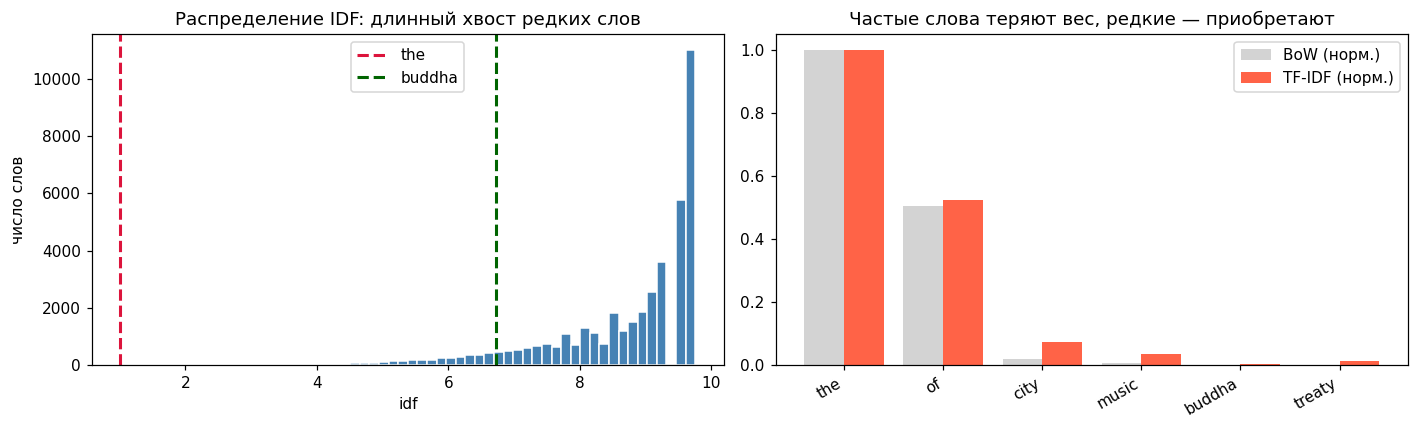

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# слева: распределение idf
axes[0].hist(idf, bins=60, color='steelblue', edgecolor='white')
axes[0].set_xlabel('idf'); axes[0].set_ylabel('число слов')
axes[0].set_title('Распределение IDF: длинный хвост редких слов')
for w, color in [('the', 'crimson'), ('buddha', 'darkgreen')]:
    if w in word2id:
        axes[0].axvline(idf[word2id[w]], color=color, ls='--', lw=2, label=w)
axes[0].legend()

# справа: как меняется вес слова при переходе BoW -> TF-IDF
words_show = ['the', 'of', 'city', 'music', 'buddha', 'treaty']
ys = [word2id[w] for w in words_show if w in word2id]
labels = [w for w in words_show if w in word2id]
bow_w = np.asarray(X_bow[:, ys].sum(0)).ravel()
bow_w = bow_w / bow_w.max()
tfidf_w = np.asarray(X_tfidf[:, ys].sum(0)).ravel()
tfidf_w = tfidf_w / tfidf_w.max()
xx = np.arange(len(labels))
axes[1].bar(xx - 0.2, bow_w, width=0.4, label='BoW (норм.)', color='lightgray')
axes[1].bar(xx + 0.2, tfidf_w, width=0.4, label='TF-IDF (норм.)', color='tomato')
axes[1].set_xticks(xx); axes[1].set_xticklabels(labels, rotation=30, ha='right')
axes[1].set_title('Частые слова теряют вес, редкие — приобретают')
axes[1].legend()
plt.tight_layout(); plt.show()

## 2.5. TF-IDF в действии

Проверим два ключевых эффекта:

1. **Поиск по ключевому слову.** Документы, где встречается редкое слово, поднимаются наверх — их не «забивают» общие слова.
2. **Кластеризация похожих документов.** Косинус стал осмысленнее.

Тонкость: у TF-IDF-вектора длина уже не имеет значения (мы делили на tf), но для устойчивости нормируем на L2.

In [12]:
# L2-нормировка строк tf-idf
def l2_normalize_rows(X):
    norms = np.sqrt(np.asarray(X.multiply(X).sum(1)).ravel()) + 1e-9
    return sp.diags(1.0 / norms) @ X

X_tfidf_n = l2_normalize_rows(X_tfidf)

def search(query, X, k=5):
    '''Поиск документов по запросу в TF-IDF-пространстве.'''
    q = [w for w in tokenize(query) if w in word2id]
    qv = sp.csr_matrix(([1.0]*len(q), ([0]*len(q), [word2id[w] for w in q])), shape=(1, V))
    qv = l2_normalize_rows(qv)
    sims = np.asarray((X @ qv.T).todense()).ravel()
    order = np.argsort(-sims)
    return [(int(j), float(sims[j])) for j in order[:k]]

for query in ['buddha meditation', 'the war', 'president election']:
    print(f'Запрос: «{query}»')
    for j, s in search(query, X_tfidf_n):
        print(f'   cos={s:.3f}  [{paragraphs[j][0]}]  {paragraphs[j][1][:70]}...')
    print()

Запрос: «buddha meditation»
   cos=0.578  [Buddhism]  Buddhist meditation is fundamentally concerned with two themes: transf...
   cos=0.511  [Buddhism]  Buddhists believe Gautama Buddha was the first to achieve enlightenmen...
   cos=0.331  [Buddhism]  In the Mahayana, the Buddha tends not to be viewed as merely human, bu...
   cos=0.326  [Buddhism]  Meditation was an aspect of the practice of the yogis in the centuries...
   cos=0.309  [Buddhism]  Samatha meditation starts from being mindful of an object or idea, whi...

Запрос: «the war»
   cos=0.513  [Seven_Years%27_War]  The war has been described as the first "world war", although this lab...
   cos=0.420  [Crimean_War]  Notable documentation of the war was provided by William Howard Russel...
   cos=0.416  [Modern_history]  The Edwardian era in the United Kingdom is the period spanning the rei...
   cos=0.401  [Ottoman_Empire]  The history of the Ottoman Empire during World War I began with the Ot...
   cos=0.391  [Military_hist

## 2.6. Итог по TF-IDF

TF-IDF — это по-прежнему «мешок слов», но с правильными весами. Это **сильнейший бейзлайн** для многих задач классификации текстов: он до сих пор обыгрывает нейросети на маленьких корпусах.

**Ограничения** остались те же: размерность $V$, разреженность, нет синонимии, нет порядка. Именно от этих проблем уходят **эмбеддинги слов** — им посвящена вся оставшаяся лекция.

---
# Часть 3. pPMI + SVD: как из «мешка» получить векторы слов

## 3.1. Ключевая идея: «слово узнаётся по компании»

До сих пор «смысл» слова мы брали из него самого — сколько раз встретилось. Но в лингвистике с 1957 года (Дж. Р. Фёрс) ходит принцип:

> **You shall know a word by the company it keeps** — слово познаётся по соседям.

Если два слова встречаются в **похожих контекстах**, они, скорее всего, близки по смыслу. `doctor` и `nurse` — не потому что похожи буквами, а потому что оба стоят рядом с `patient`, `hospital`, `treatment`.

Формализуем: построим матрицу **«слово × контекст»** (сколько раз слово `w` встречалось рядом с контекстным словом `c`), а затем сожмём её в плотные векторы.

## 3.2. Корпус для эмбеддингов

Для эмбеддингов нужен корпус побольше, чем для демонстрации BoW. Возьмём первые 40 000 предложений (~1.1 млн токенов). Ограничим словарь: слова с частотой $\ge 5$, максимум 6 000 самых частых. Так эмбеддинги успеют «начитаться» каждого слова.

Сначала построим **токенизированный корпус** — список списков id слов.

In [13]:
CORPUS_SIZE = 40000
MAX_VOCAB   = 6000
MIN_COUNT   = 5
WINDOW      = 5          # размер контекстного окна (по 5 слов в каждую сторону)

corpus_sentences = all_sentences[:CORPUS_SIZE]
corpus_tokens = [tokenize(s) for s in corpus_sentences]

# ---------- словарь эмбеддингов ----------
token_freq = collections.Counter()
for toks in corpus_tokens:
    token_freq.update(toks)

words = [w for w, c in token_freq.most_common(MAX_VOCAB) if c >= MIN_COUNT]
w2i = {w: i for i, w in enumerate(words)}
V_emb = len(words)

# корпус в виде id
corpus_ids = [[w2i[w] for w in toks if w in w2i] for toks in corpus_tokens]

n_tokens = sum(len(ids) for ids in corpus_ids)
print(f'предложений в корпусе эмбеддингов: {len(corpus_sentences):,}')
print(f'токенов (в словаре):               {n_tokens:,}')
print(f'размер словаря эмбеддингов:        {V_emb:,}')
print(f'покрытие корпуса словарём:         {n_tokens / sum(len(t) for t in corpus_tokens):.1%}')

предложений в корпусе эмбеддингов: 40,000
токенов (в словаре):               830,548
размер словаря эмбеддингов:        6,000
покрытие корпуса словарём:         86.6%


## 3.3. Матрица совместной встречаемости

Проходим по каждому предложению и для каждого слова $w$ смотрим слова $c$ в окне `WINDOW` вокруг него. Пара $(w, c)$ считается один раз за появление.

**Тонкость — вес пары.** Не все соседи одинаково важны: слово на расстоянии 1 говорит о смысле больше, чем на расстоянии 5. Поэтому взвесим пару как $1 / |i - j|$ (чем дальше, тем меньше вклад). Плюс симметризуем матрицу ($co[w,c] += co[c,w]$), чтобы `cat ↔ eats` влияло и на `cat`, и на `eats`.

Матрица получается разреженной: $6000 \times 6000$, но ненулевых пар — лишь $\sim 1.5$ млн.

In [14]:
def cooccurrence(corpus_ids, vocab_size, window=5):
    '''Взвешенная матрица «слово × контекст», симметризованная.'''
    rows, cols, vals = [], [], []
    for ids in corpus_ids:
        L = len(ids)
        for i in range(L):
            wi = ids[i]
            for j in range(max(0, i - window), min(L, i + window + 1)):
                if i == j:
                    continue
                rows.append(wi); cols.append(ids[j]); vals.append(1.0 / abs(i - j))
    co = sp.coo_matrix((vals, (rows, cols)), shape=(vocab_size, vocab_size)).tocsr()
    return co + co.T          # симметризуем: co[w,c] == co[c,w]

t0 = time.time()
co = cooccurrence(corpus_ids, V_emb, WINDOW)
print(f'матрица co: {co.shape}, ненулевых: {co.nnz:,}, время: {time.time()-t0:.1f} c')
print(f'плотность: {co.nnz / V_emb**2:.2%}  (матрица разреженная!)')

# частые слова-контексты для примера
for w in ['king', 'buddha', 'music']:
    if w in w2i:
        row = co.getrow(w2i[w]).toarray().ravel()
        top = np.argsort(-row)[:6]
        print(f'  частые соседи «{w}»: ' + ', '.join(words[j] for j in top))

матрица co: (6000, 6000), ненулевых: 1,884,056, время: 5.0 c
плотность: 5.23%  (матрица разреженная!)
  частые соседи «king»: the, of, and, in, to, as
  частые соседи «buddha»: the, of, and, gautama, to, a
  частые соседи «music»: the, and, of, in, to, classical


## 3.4. Почему нельзя факторизовать матрицу счётчиков «как есть»

Сырые частоты совстречаемости сильно перекошены: у частых слов (`the`, `of`) огромные числа, у редких — крошечные. Если факторизовать такую матрицу напрямую, доминировать будут частотные слова, а не смысловые связи.

**PMI (Pointwise Mutual Information)** нормирует на частоты и измеряет: *насколько чаще слова встречаются вместе, чем ожидалось бы при независимости*.

$$\mathrm{PMI}(w, c) = \log \frac{P(w, c)}{P(w)\,P(c)} = \log \frac{\#(w,c)\cdot \text{total}}{\#(w)\cdot \#(c)}$$

где $\#(w,c)$ — вес пары из матрицы, $\#(w)$ — сумма по строке, `total` — сумма всей матрицы.

* $\mathrm{PMI} > 0$ — слова ходят вместе чаще случайного;
* $\mathrm{PMI} \approx 0$ — независимы;
* $\mathrm{PMI} < 0$ — избегают друг друга.

**Проблема:** PMI бывает очень большим для редких слов (одна встреча «вместе» — уже огромный PMI) и отрицательным для редких, встретившихся случайно. Лечение — **Positive PMI**: просто обрезаем отрицательные значения в ноль: $\mathrm{PPMI} = \max(\mathrm{PMI}, 0)$.

Именно PPMI-матрицу (pPMI) и факторизуют.

In [15]:
def ppmi_matrix(co):
    '''Positive PMI. Возвращает разреженную PPMI-матрицу.'''
    coo = co.tocoo()
    total = coo.data.sum()
    row_sum = np.asarray(co.sum(1)).ravel()
    col_sum = np.asarray(co.sum(0)).ravel()
    # считаем PMI только для ненулевых элементов
    pmi = np.log((coo.data * total) / (row_sum[coo.row] * col_sum[coo.col]))
    pmi = np.maximum(pmi, 0.0)                        # -> PPMI
    return sp.csr_matrix((pmi, (coo.row, coo.col)), shape=co.shape)

t0 = time.time()
P = ppmi_matrix(co)
print(f'PPMI: ненулевых {P.nnz:,} (было {co.nnz:,}), время {time.time()-t0:.1f} c')

# пример: сильные связи (высокий PPMI)
def top_pairs(P, k=12):
    coo = P.tocoo()
    order = np.argsort(-coo.data)[:k]
    return [(words[coo.row[i]], words[coo.col[i]], round(float(coo.data[i]), 2)) for i in order]
print()
print('пары с самым высоким PPMI:')
for a, b, v in top_pairs(P):
    print(f'   {a:14s} — {b:14s}  {v}')

PPMI: ненулевых 1,884,056 (было 1,884,056), время 0.1 c

пары с самым высоким PPMI:
   pusan          — perimeter       9.19
   perimeter      — pusan           9.19
   buenos         — aires           9.15
   aires          — buenos          9.15
   arabia         — saudi           9.11
   saudi          — arabia          9.11
   intelligible   — mutually        8.98
   mutually       — intelligible    8.98
   habeas         — corpus          8.98
   corpus         — habeas          8.98
   fierce         — sasha           8.93
   sasha          — fierce          8.93


## 3.5. Усечённое SVD: сжатие $V \times V$ в $V \times d$

Теперь у нас есть PPMI-матрица $V \times V$. Хотим для каждого слова получить **вектор длины $d \ll V$**. Это классическая задача **низкорангового приближения**:

$$P \approx U \Sigma V^\top, \qquad U \in \mathbb{R}^{V \times d},\ \Sigma \in \mathbb{R}^{d \times d}$$

Строки $U$ — это и есть эмбеддинги слов. Почему это работает? SVD находит $d$ «главных направлений» изменчивости PPMI; почти вся структура (кто с кем связан) укладывается в первое $d$ измерений. Это ровно метод **LSA/LSI** (Latent Semantic Analysis, Deerwester и др., 1990).

Практический вариант — **усечённое SVD** (`svds`): не считаем полную матрицу, а берём только $d$ наибольших сингулярных троек. Бонус: $U\sqrt{\Sigma}$ считается стандартным улучшением качества (уравнивает масштаб осей).

Возьмём $d = 100$.

In [16]:
from scipy.sparse.linalg import svds

def svd_embeddings(P, dim=100):
    '''Усечённое SVD: возвращает (V, dim) эмбеддинги, L2-нормированные.'''
    u, s, vt = svds(P, k=dim)              # u: (V, dim), s: (dim,)
    E = u * np.sqrt(s)                     # классический трюк: U * sqrt(Sigma)
    E = E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-9)
    return E

t0 = time.time()
DIM = 100
E_svd = svd_embeddings(P, DIM)
print(f'эмбеддинги PPMI+SVD: {E_svd.shape}, время {time.time()-t0:.1f} c')

эмбеддинги PPMI+SVD: (6000, 100), время 4.4 c


## 3.6. Проверяем качество: ближайшие соседи и аналогии

Главные тесты «на глаз»:

1. **Ближайшие соседи**: у `king` должны быть `queen`, `prince`, `имена королей`.
2. **Аналогии**: `king − man + woman ≈ queen` (векторная арифметика на смыслах!). Работает, если направления «пол» и «королевская власть» линейно разделимы в пространстве.

Пишем функции `nearest` и `analogy` — они пригодятся и для других методов.

In [17]:
def nearest(E, word, k=6):
    '''k ближайших слов по косинусу.'''
    if word not in w2i:
        return None
    sims = E @ E[w2i[word]]
    order = np.argsort(-sims)[:k + 1]
    return [(words[i], round(float(sims[i]), 2)) for i in order if i != w2i[word]]

def analogy(E, a, b, c, k=5):
    '''a : b === c : ?  =>  вектор b - a + c.'''
    if not all(x in w2i for x in (a, b, c)):
        return None
    v = E[w2i[b]] - E[w2i[a]] + E[w2i[c]]
    v = v / (np.linalg.norm(v) + 1e-9)
    sims = E @ v
    order = np.argsort(-sims)[:k + 6]
    return [(words[i], round(float(sims[i]), 2))
            for i in order if words[i] not in (a, b, c)][:k]

print('=== Ближайшие соседи (PPMI+SVD) ===')
for w in ['king', 'music', 'war', 'city', 'water']:
    print(f'{w:8s} ->', nearest(E_svd, w))

print()
print('=== Аналогии (PPMI+SVD) ===')
for a, b, c in [('man', 'king', 'woman'), ('france', 'paris', 'italy')]:
    print(f'{a} : {b} === {c} : ?   ->', analogy(E_svd, a, b, c))

=== Ближайшие соседи (PPMI+SVD) ===
king     -> [('henry', 0.82), ('philip', 0.77), ('vi', 0.76), ('ii', 0.75), ('vii', 0.75), ('iv', 0.74)]
music    -> [('dance', 0.68), ('artists', 0.68), ('songs', 0.66), ('disco', 0.66), ('pop', 0.65), ('genre', 0.63)]
war      -> [('wars', 0.65), ('invasion', 0.61), ('battle', 0.59), ('defeat', 0.57), ('forces', 0.56), ('conflict', 0.56)]
city     -> [('york', 0.77), ('metropolitan', 0.75), ('oklahoma', 0.73), ('area', 0.71), ('district', 0.7), ('downtown', 0.68)]
water    -> [('sunlight', 0.61), ('waste', 0.6), ('solar', 0.58), ('hydrogen', 0.58), ('carbon', 0.58), ('heating', 0.57)]

=== Аналогии (PPMI+SVD) ===
man : king === woman : ?   -> [('henry', 0.62), ('philip', 0.62), ('throne', 0.58), ('duke', 0.58), ('prince', 0.57)]
france : paris === italy : ?   -> [('chopin', 0.46), ('1810', 0.44), ('1835', 0.43), ('torch', 0.43), ('route', 0.43)]


Соседи выглядят осмысленно. А вот аналогии на нашем корпусе (всего 40 000 предложений) шумные — и это **ожидаемо**: чтобы направление «страна → столица» или «мужчина → женщина» стало линейным в пространстве, нужен корпус на порядки больше. Аналогии — свойство больших корпусов, а не магия одной формулы. Запомним этот тезис, он пригодится в части 6.

## 3.7. Визуализация: карта смыслов

Чтобы увидеть структуру, спроецируем эмбеддинги на плоскость через **t-SNE** (t-распределённое стохастическое вложение соседей). t-SNE сохраняет *локальные* окрестности: похожие слова оказываются рядом. Возьмём 400 самых частых слов.

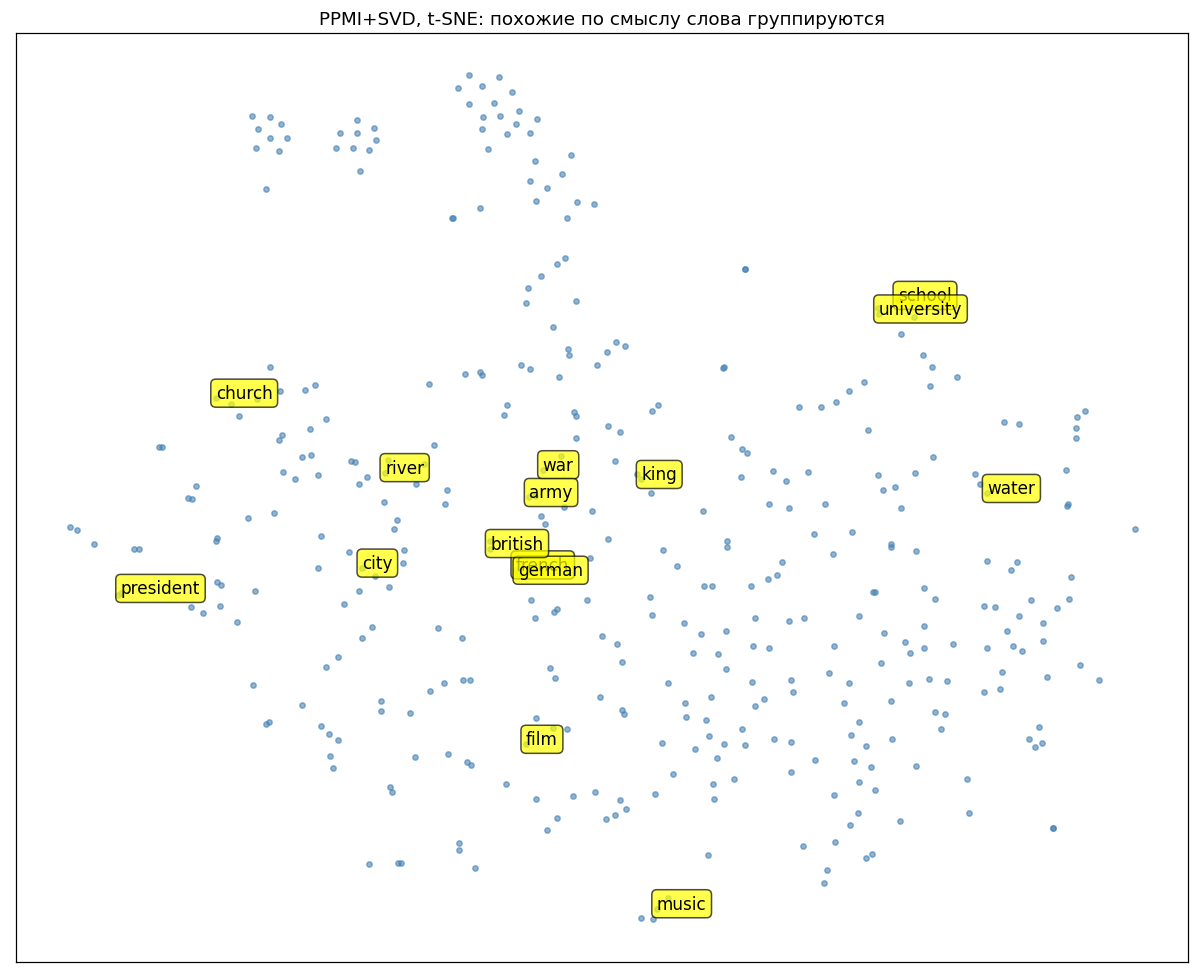

In [18]:
from sklearn.manifold import TSNE

frequent = [w for w in words if token_freq[w] >= 60][:400]
frequent_idx = [w2i[w] for w in frequent]

ts = TSNE(n_components=2, perplexity=25, random_state=SEED, init='pca', learning_rate='auto')
proj = ts.fit_transform(E_svd[frequent_idx])

plt.figure(figsize=(11, 9))
plt.scatter(proj[:, 0], proj[:, 1], s=12, color='steelblue', alpha=0.6)
# подпишем самые интересные/интуитивно понятные слова
interesting = ['king', 'queen', 'prince', 'war', 'army', 'soldiers', 'music', 'song',
               'city', 'town', 'river', 'water', 'president', 'election', 'church', 'god',
               'french', 'german', 'british', 'school', 'university', 'film', 'book']
for w in interesting:
    if w in w2i and w in frequent:
        j = frequent.index(w)
        plt.annotate(w, (proj[j, 0], proj[j, 1]), fontsize=11,
                     bbox=dict(boxstyle='round', fc='yellow', alpha=0.7))
plt.title('PPMI+SVD, t-SNE: похожие по смыслу слова группируются')
plt.xticks([]); plt.yticks([])
plt.tight_layout(); plt.show()

## 3.8. Итог по pPMI + SVD

Мы прошли путь: **счёт пар → PMI → PPMI → SVD → плотные векторы**. Это работающий метод (LSA), но у него есть слабости:

* SVD — дорогая операция, а матрицу $V \times V$ надо держать целиком;
* не очень понятно, *как именно* считать контекст (окно? вес?);
* качество на аналогиях обычно хуже, чем у word2vec/GloVe;
* на больших словарях ($\ge 10^6$) всё упирается в память.

Именно эти недостатки мотивировали **word2vec** — обучать векторы напрямую, а не факторизовать матрицу. О нём — следующая часть, но там у нас **только теория**: реализацию писать не будем.

---
# Часть 4. word2vec — только теория

> **Важно.** Эту часть мы **не реализуем в коде**. По заданию лекции: разбираем «на бумаге» архитектуру и обучение word2vec, но писать CBOW/Skip-gram не будем — вместо этого покажем GloVe (часть 6) и FastText (часть 5), у которых свои цели обучения.

## 4.1. Что это и почему прорыв

**word2vec** (Mikolov et al., 2013) — набор моделей, которые учатся строить эмбеддинги слов **нейросетью, но очень дешёвой**. Главные идеи:

* цель обучения — **предсказание контекста**, а не язык-модель и не перевод;
* получаемые векторы обладают **линейной структурой**: `king − man + woman ≈ queen`;
* обучение шло на миллиардах слов за часы — в 2013 это было сенсацией.

Модель маленькая (один скрытый слой без нелинейности), но именно поэтому и быстрая. Парадокс: «нейросеть» здесь — просто матрица $V \times d$, а вся магия в постановке задачи.

## 4.2. Две архитектуры

**CBOW (Continuous Bag of Words)** — по контексту предсказываем центральное слово.

```text
   контекст:  [the, king, is, a]        (окно 2 слева/справа)
                     │
        ┌────────────┴────────────┐
        │  усредняем их векторы    │   h = (E[w_{t-2}] + E[w_{t-1}] + E[w_{t+1}] + E[w_{t+2}]) / 4
        └────────────┬────────────┘
                     │  h ∈ R^d
                     ▼
        ┌──────────────────────────┐
        │ выходной слой: софтмакс  │   p(w | контекст)
        │ по ВСЕМУ словарю (V)     │
        └──────────────────────────┘
                     │
                     ▼
              предсказано: "man"
```

**Skip-gram** — наоборот: по центральному слову предсказываем **каждый** контекстный.

```text
                    центральное слово: "king"
                             │
                             ▼
                   E["king"] = v ∈ R^d
                             │
        ┌──────┬────────┬────┴───┬────────┐
        ▼      ▼        ▼        ▼        ▼
      "the"  ...      "is"     "a"     "man"     (предсказываем каждое отдельно)
        │      │        │        │        │
        └──────┴────────┴────────┴────────┘
                 софтмакс по словарю V для каждого
```

Формулы:

$$p(c \mid w) = \frac{\exp(E'_c \cdot E_w)}{\sum_{c' \in \mathcal{V}} \exp(E'_{c'} \cdot E_w)}$$

где $E_w$ — «входной» вектор слова (как слова), $E'_c$ — «выходной» вектор (как контекста). У каждого слова **две** роли — быть центром и быть контекстом, а потому две матрицы $E$ и $E'$.

**Что выбрать.** Skip-gram лучше на редких словах и даёт чуть более качественные аналогии (особенно с окном 5–10). CBOW быстрее и чуть лучше на частотных словах. На практике обычно берут Skip-gram с negative sampling.

## 4.3. Почему нельзя просто взять софтмакс

Знаменатель софтмакса — сумма по **всему словарю** $V$. На каждом шаге обучения мы бы считали и обновляли миллионы параметров ради одного примера. Это фатально медленно.

**Решение — negative sampling.** Идея: превратить $V$-классовую задачу в набор бинарных. Для пары $(w, c)$, которая реально встретилась вместе (положительный пример), берём $k$ случайных «чужих» контекстов (негативные примеры, $k \approx 5$–$20$) и учимся отличать их:

$$\mathcal{L} = \underbrace{\log \sigma(E'_c \cdot E_w)}_{\text{«да», они вместе}} + \sum_{i=1}^{k} \underbrace{\log \sigma(-E'_{c_i} \cdot E_w)}_{\text{«нет», шум}}$$

Максимизируем $\mathcal{L}$ (или минимизируем $-\mathcal{L}$). Теперь на шаг — $k+1$ обновлений вместо $V$. Это и есть главный трюк word2vec.

**Как выбирать негативы?** Не равномерно: частые слова-шум встречались бы слишком часто. Берут распределение $\propto f(w)^{3/4}$, где $f(w)$ — частота слова. Степень $\tfrac34$ эмпирически «выравнивает» хвост.

## 4.4. Тренировка: рецепт и трюки

Обучение — это просто **SGD по парам «слово–контекст»**, извлечённым из корпуса скользящим окном. Полный рецепт:

1. **Пройти корпус окном.** Для каждого слова — контекст из $2m$ соседей ($m$ — «полуокно», обычно 5).
2. **Случайный размер окна.** Не фиксируйте $m$: для каждого слова берите $m' \sim \mathrm{Uniform}(1, m)$. Частые слова и так учатся хорошо; случайность окна даёт более «широкие» отношения.
3. **Субсэмплинг частых слов (subsampling).** Слово $w$ выбрасывается с вероятностью
   $$p_{\text{drop}}(w) = 1 - \sqrt{\frac{t}{f(w)}}\quad (t \approx 10^{-5})$$
   Это убирает бесполезные `the`, `of` и ускоряет обучение в разы, не теряя качества.
4. **Negative sampling** с распределением $f^{3/4}$, $k$ негативов.
5. **SGD/Adagrad**, взять $d = 100$–$300$, и задать learning rate, убывающий к концу.

**Почему нелинейности нет?** Внутри — только скалярные произведения $E'_c \cdot E_w$. Добавь ReLU — и задача станет нелинейной, но именно простота даёт скорость и линейные аналогии.

## 4.5. Связь с PPMI (необязательно, но красиво)

Оказалось (Levy & Goldberg, 2014), что **SGNS неявно факторизует сдвинутую PPMI-матрицу**: на оптимуме $E_w \cdot E'_c = \mathrm{PMI}(w,c) - \log k$. То есть word2vec и PPMI+SVD решают очень похожую задачу — только первый учится по парам-примерам (SGD), а второй факторизует матрицу целиком.

Это прекрасно объясняет, почему результаты двух методов так похожи, а **hyperparameters** (размер окна, $k$) в word2vec на самом деле управляют тем, *какую именно* матрицу он факторизует. Подробнее — в статье Levy, Goldberg, Dagan (2015) «Improving Distributional Similarity with Lessons Learned from Word Embeddings».

## 4.6. Практические заметки

* **window size** задаёт семантику: большое окно (10) → тематическая близость (`dog` ~ `cat`), маленькое (2) → синтаксическая/функциональная (`dog` ~ `dogs`, `run` ~ `running`).
* **$d$**: 100–300 для общих задач; больше данных → можно больше.
* **Как получить вектор документа** (у word2vec нет такого понятия): усреднить векторы слов (просто, но теряет порядок) или обучить сверху что-то ещё. Это делает word2vec «неудобным» для классификации — в отличие от BoW.
* **Ограничение по сути то же**, что у PPMI: у каждого слова **один** вектор, а слово многозначно (`bank` — река/счёт). Контекстные эмбеддинги (ELMo/BERT) решают это уже в следующей лекции.

> **Вывод.** word2vec — это CBOW/Skip-gram, обучение предсказанию контекста через negative sampling, с субсэмплингом частых слов и скользящим окном. Реализацию мы сознательно опускаем; в части 6 увидим GloVe — альтернативу, которую обучим сами и сравним с PPMI+SVD.

---
# Часть 5. FastText: слова из кусочков

## 5.1. Проблема, которую решает FastText

И word2vec, и pPMI+SVD хранят **один вектор на целое слово**. Отсюда две беды:

1. **OOV (out-of-vocabulary).** Слово, которого не было в обучающем корпусе, вообще не имеет вектора. Ошибка в один символ — и `hospital` превращается в незнакомца.
2. **Морфология.** `run`, `runs`, `running`, `runner` — семантически родственные, но в словаре это четыре независимых слова с никак не связанными векторами. Для русского, где форм ещё больше, беда усиливается.

**FastText** (Bojanowski et al., 2017, тот же коллектив, что и word2vec) предлагает элегантное решение: представить слово как **сумму векторов его символьных n-грамм**.

Родная идея: «word» — это не атом, а набор кусочков. `running` = вектор от `run`, от `runn`, от `unnin`, от `ing`, от `<run`, от `ning>` и т.д.

## 5.2. Архитектура

```text
   слово "king"  (не забудь про границы:  <king> )
        │
        ├── n=3:  <ki, kin, ing, ng>
        ├── n=4:  <kin, king, ing>
        └── n=5:  <king, king>
        │        (+ само слово целиком как отдельный "n-грамм")
        ▼
   ┌────────────────────────────────────────────┐
   │ E["<ki"] + E["kin"] + E["ing"] + ... + E["king"] │
   └────────────────────────────────────────────┘
        │  сумма векторов n-грамм
        ▼
   вектор слова E["king"] ∈ R^d
        │
        ▼
   тот же objective, что у word2vec:
   Skip-gram + Negative Sampling  (или подобный)
```

Обратите внимание: **обучаемая** величина — не слова, а **n-граммы** (обычно $3 \le n \le 6$, плюс само слово). Вектор слова складывается из n-грамм на лету.

**Что это даёт:**

* **OOV решается сам.** Незнакомое слово состоит из знакомых кусочков — вектор есть всегда.
* **Общий смысл у морфологических форм.** `run`, `runs`, `running` делят n-граммы `run`, `ing`, `s` — и сближаются.
* **Опечатки переносятся мягко.** `hospitla` делит большинство n-грамм с `hospital`.
* **Цена:** векторов надо учить во много раз больше (миллионы n-грамм), обучение медленнее, а словарь n-грамм занимает память. Обычно ограничиваются хешированием в фиксированную таблицу.

## 5.3. Обучение

Обучение — **то же самое, что у word2vec/Skip-gram с negative sampling** (обсуждали в части 4), но с одним отличием: градиент растекается не в вектор слова, а в **все его n-граммы**.

1. Строим пары «слово — контекст» скользящим окном.
2. Для слова собираем его n-граммы, суммируем их векторы → вектор слова.
3. Считаем SGNS-лосс: максимизируем $\log\sigma(E_{c}\cdot E_w) + \sum_i \log\sigma(-E_{c_i}\cdot E_w)$.
4. Backprop обновляет векторы **всех n-грамм**, из которых составлено слово.
5. Субсэмплинг частых слов и $f^{3/4}$ для негативов — как в word2vec.

На выходе — таблица векторов n-грамм. Вектор произвольного слова — сумма его n-грамм (включая само слово). Из-за этого FastText временами обыгрывает word2vec на аналогиях и заметно лучше на редких словах.

> Реализацию SGNS-обучения мы, как и для word2vec, не пишем. Ниже используем **вторую известную ипостась FastText** — быстрый **классификатор текстов** — и покажем работу с n-граммами руками.

## 5.4. Вторая ипостась FastText: классификатор текстов

В статьях «Bag of Tricks for Efficient Text Classification» (Joulin et al., 2016) и «FastText.zip» (2016) тот же инструмент применён к **классификации**: текст → средний вектор его слов и n-грамм → линейный слой на классы.

```text
   предложение: "the buddha taught ..."
        │ токены + char n-граммы каждого токена
        ▼
   ┌───────────────────────────────┐
   │ среднее векторов фич (мешок)  │  h = mean(E[фичи])
   └───────────────────────────────┘
        │
        ▼
   линейный слой + softmax по темам
```

Ключевая фишка: n-граммы дают **устойчивость к опечаткам и к редким/новым словам**, а линейность — скорость. Ниже мы построим именно такой классификатор вручную (хешированные признаки) и сравним его с BoW.

## 5.5. n-граммы руками

Реализуем извлечение символьных n-грамм с маркерами границ `<...>` (границы важны: они различают префиксы и суффиксы).

In [19]:
def char_ngrams(word, nmin=3, nmax=5, boundaries=True):
    '''Символьные n-граммы слова. Границы '<', '>' различают префиксы и суффиксы.'''
    w = ('<' + word + '>') if boundaries else word
    grams = []
    for n in range(nmin, nmax + 1):
        for i in range(len(w) - n + 1):
            grams.append(w[i:i + n])
    return grams

for w in ['king', 'running', 'buddhism']:
    g = char_ngrams(w)
    print(f'{w:10s} ({len(g):2d} n-грамм): {g[:10]} ...')

print()
print('Как n-граммы ловят морфологию:')
for w in ['run', 'runs', 'running', 'runner']:
    print(f'  {w:8s} -> {set(char_ngrams(w, 3, 3))}')

king       ( 9 n-грамм): ['<ki', 'kin', 'ing', 'ng>', '<kin', 'king', 'ing>', '<king', 'king>'] ...
running    (18 n-грамм): ['<ru', 'run', 'unn', 'nni', 'nin', 'ing', 'ng>', '<run', 'runn', 'unni'] ...
buddhism   (21 n-грамм): ['<bu', 'bud', 'udd', 'ddh', 'dhi', 'his', 'ism', 'sm>', '<bud', 'budd'] ...

Как n-граммы ловят морфологию:
  run      -> {'run', '<ru', 'un>'}
  runs     -> {'run', '<ru', 'uns', 'ns>'}
  running  -> {'unn', 'run', 'nni', 'ing', '<ru', 'ng>', 'nin'}
  runner   -> {'unn', 'run', '<ru', 'ner', 'nne', 'er>'}


## 5.6. Как n-граммы «понимают» незнакомые слова

Покажем главный трюк FastText: **похожесть неизвестного слова с известными** можно оценить по пересечению n-грамм, даже не имея вектора. Это и есть интуиция, которая спасает при OOV.

In [20]:
def ngram_overlap(a, b, nmin=3, nmax=5):
    '''Жаккар по символьным n-граммам между двумя словами.'''
    A, B = set(char_ngrams(a, nmin, nmax)), set(char_ngrams(b, nmin, nmax))
    return len(A & B) / len(A | B)

print('Жаккар по n-граммам (насколько слова "похожи" фонетически):')
for a, b in [('running', 'run'), ('hospital', 'hospitial'), ('king', 'queen'),
             ('buddhism', 'buddhist'), ('cat', 'car'), ('king', 'xqz')]:
    print(f'  {a:10s} ~ {b:10s}  {ngram_overlap(a, b):.2f}')

print()
print('Незнакомое слово "buddhist" частично объясняется словом "buddhism":')
print('  общие n-граммы:', sorted(set(char_ngrams('buddhist', 4, 4)) &
                                    set(char_ngrams('buddhism', 4, 4))))

Жаккар по n-граммам (насколько слова "похожи" фонетически):
  running    ~ run         0.14
  hospital   ~ hospitial   0.41
  king       ~ queen       0.00
  buddhism   ~ buddhist    0.56
  cat        ~ car         0.09
  king       ~ xqz         0.00

Незнакомое слово "buddhist" частично объясняется словом "buddhism":
  общие n-граммы: ['<bud', 'budd', 'ddhi', 'dhis', 'uddh']


## 5.7. FastText-классификатор текстов

Соберём классификатор «мешок n-грамм + логистическая регрессия». Каждое предложение → вектор в разреженном пространстве хешированных признаков (слова + их символьные n-граммы). Тот же принцип, что и в fastText-классификаторе.

Тему для примера дадим чуть позже (в части 7 сравниваем все методы на **одной** задаче), а здесь посмотрим демо: `the` (очень частое слово) и редкие слова получат одинаковый «шанс», а n-граммы добавят живучести.

In [21]:
from scipy.sparse import csr_matrix

def featurize_text(text, D=2**16, nmin=3, nmax=5):
    '''Хешированные признаки: слова + символьные n-граммы. Возвращает (indices, counts).'''
    feats = []
    for t in tokenize(text):
        feats.append('w_' + t)                      # слово целиком
        feats += ['c_' + g for g in char_ngrams(t, nmin, nmax)]
    hashed = [hash(f) % D for f in feats]
    feat_idx, feat_cnt = np.unique(hashed, return_counts=True)
    return feat_idx, feat_cnt

demo = "the buddha taught meditation in ancient india"
feat_idx, feat_cnt = featurize_text(demo)
print(f'«{demo}»')
print(f'  слов: {len(tokenize(demo))}, признаков (слов+ngrams) после хеширования: {len(feat_idx)}')
print(f'  первые признаки: {feat_idx[:10]}')

# почему FastText устойчив: одно опечатанное/новое слово всё ещё шэрит n-граммы
word = 'meditation'
print(f'\nВектор слова «{word}» состоит из {len(char_ngrams(word))} n-грамм; '
      f'даже если слово новое, ненулевых признаков много.')

«the buddha taught meditation in ancient india»
  слов: 7, признаков (слов+ngrams) после хеширования: 102
  первые признаки: [  62  590 1021 1204 5479 5713 6620 6621 8720 8885]

Вектор слова «meditation» состоит из 27 n-грамм; даже если слово новое, ненулевых признаков много.


## 5.8. Итог по FastText

**FastText = word2vec + символьные n-граммы.** Вектор слова — сумма векторов его кусочков, поэтому:

* нет проблемы OOV;
* морфология работает;
* опечатки переносятся мягко;
* цена — больше параметров и медленнее обучение.

Плюс у FastText есть отдельная сильная ипостась — **быстрый линейный классификатор текстов** на мешке n-грамм, который мы и использовали в демо. Точно такой же мы прогоним в сравнении (часть 7).

---
# Часть 6. GloVe: глобальные векторы

## 6.1. Идея

**GloVe** (Global Vectors, Pennington, Socher, Manning, 2014) задаёт вопрос: *почему бы не обучать эмбеддинги на глобальной статистике совместной встречаемости напрямую, своей функцией потерь?* Не факторизовать готовую PPMI (как SVD), а **подгонять** скалярные произведения векторов под логарифмы частот по лоссу.

Отправная точка — наблюдение: отношения совместных вероятностей кодируют смысл. Для слова $w$ и контекстов:

$$\frac{P(\text{solid} \mid \text{ice})}{P(\text{solid} \mid \text{steam})} \gg 1,\qquad
\frac{P(\text{gas} \mid \text{ice})}{P(\text{gas} \mid \text{steam})} \ll 1$$

`ice` и `steam` близки (обе — вода), различает их *контекст*: `solid` vs `gas`. Идея GloVe — подобрать векторы так, чтобы **разности** векторов воспроизводили эти отношения.

## 6.2. Функция потерь

GloVe постулирует, что $E_w \cdot E'_c + b_w + b_c \approx \log X_{wc}$, где $X_{wc}$ — наблюдаемая совместная встречаемость (сырые счётчики!), $b_w, b_c$ — смещения слов. Отсюда **взвешенная квадратичная ошибка**:

$$\mathcal{L} = \sum_{w, c} f(X_{wc})\,\big(E_w \cdot E'_c + b_w + b_c - \log X_{wc}\big)^2$$

**Зачем вес $f(X_{wc})$?** Он решает две проблемы:

1. Пары с $X_{wc} = 0$ надо игнорировать (иначе лосс требует $\log 0$) — при $f(0) = 0$ они выпадают автоматически.
2. Частые пары (`the–of`) не должны доминировать: лосс насыщается, $f$ перестаёт расти. Слишком редкие пары, наоборот, шумят.

Стандартный выбор (так, чтобы $f(1) = 1$, то есть редкие пары не подавлялись):

$$f(x) = \begin{cases} (x / x_{\max})^{\alpha}, & x < x_{\max} \\ 1, & x \ge x_{\max} \end{cases}
\qquad \alpha = 0.75,\quad x_{\max} = 100$$

**Почему $\log$ счётчиков?** Совстречаемость растёт мультипликативно, а смысл — аддитивен: `king` и `queen` «одинаковы плюс пол». Логарифм превращает умножение частот в сложение векторов — именно то, что нужно для линейных аналогий.

**Почему $\alpha = 0.75$?** Эмпирика авторов: если вес слишком быстро растёт ($\alpha$ близко к 1), редкие пары недополучают внимания; если слишком медленно — частые шумят. $0.75$ — компромисс, тот же показатель степени, что и в негативном сэмплинге word2vec.

## 6.3. Связь с word2vec и PPMI

Все три метода — про одно: **скалярное произведение векторов кодирует лог-частоту совместной встречаемости**.

* **SVD**: факторизует PPMI-матрицу аналитически.
* **word2vec (SGNS)**: на оптимуме $E_w \cdot E'_c = \mathrm{PMI}(w,c) - \log k$.
* **GloVe**: подгоняет $E_w \cdot E'_c + b_w + b_c$ под $\log X_{wc}$.

GloVe убирает недостатки обоих: он, как word2vec, сэмплирует из пар (не нужна матрица целиком в памяти) — но, как SVD, использует **всю глобальную статистику** и не страдает от нестабильности SGD на редких парах.

## 6.4. Обучаем GloVe сами

Реализуем всё на чистом PyTorch: параметры `W` (слово), `Wt` (контекст), смещения `bw`, `bt`. Каждый шаг — случайный мини-батч пар из матрицы совстречаемости, лосс по формуле выше. Оптимизатор — Adagrad (исторический выбор для GloVe: разные слова встречаются с разной частотой, адаптивный шаг помогает).

Сначала подготовим данные: пары $(w, c, X_{wc})$ и разделим их на train/test 90/10 для честной проверки.

In [22]:
# пары (слово, контекст, счётчик) из матрицы совместной встречаемости
coo = co.tocoo()
n_pairs = coo.nnz
Xi = coo.row.astype(np.int64)
Xj = coo.col.astype(np.int64)
Xv = coo.data.astype(np.float32)

# train/test split по парам
rng = np.random.default_rng(SEED)
perm = rng.permutation(n_pairs)
n_train = int(0.9 * n_pairs)
tr, te = perm[:n_train], perm[n_train:]

# переносим на устройство
def to_device(a, dtype):
    return torch.tensor(a, dtype=dtype, device=device)

Xi_tr, Xj_tr, Xv_tr = to_device(Xi[tr], torch.long), to_device(Xj[tr], torch.long), to_device(Xv[tr], torch.float32)
Xi_te, Xj_te, Xv_te = to_device(Xi[te], torch.long), to_device(Xj[te], torch.long), to_device(Xv[te], torch.float32)

print(f'пар всего:  {n_pairs:,}')
print(f'  train:    {len(tr):,}')
print(f'  test:     {len(te):,}')
print(f'X_max (частота): {Xv.max():.0f}, X_min: {Xv.min():.4f}')

пар всего:  1,884,056
  train:    1,695,650
  test:     188,406
X_max (частота): 45241, X_min: 0.4000


In [23]:
class GloVe(nn.Module):
    '''GloVe: обучаемые эмбеддинги слов и контекстов + смещения.'''
    def __init__(self, vocab_size, dim, x_max=100.0, alpha=0.75):
        super().__init__()
        self.x_max, self.alpha = x_max, alpha
        self.W  = nn.Embedding(vocab_size, dim)    # векторы слов
        self.Wt = nn.Embedding(vocab_size, dim)    # векторы контекстов
        self.bw = nn.Embedding(vocab_size, 1)
        self.bt = nn.Embedding(vocab_size, 1)
        # инициализация как в оригинале: Uniform(-0.5/d, 0.5/d), смещения = 0
        for emb in (self.W, self.Wt):
            nn.init.uniform_(emb.weight, -0.5 / dim, 0.5 / dim)
        nn.init.zeros_(self.bw.weight)
        nn.init.zeros_(self.bt.weight)

    def forward(self, i, j, x):
        '''Взвешенная квадратичная ошибка с лог-частотой.'''
        pred = (self.W(i) * self.Wt(j)).sum(-1) + self.bw(i).squeeze(-1) + self.bt(j).squeeze(-1)
        diff = pred - torch.log(torch.clamp(x, min=1e-9))
        weight = torch.clamp(x, max=self.x_max).pow(self.alpha)
        return (weight * diff ** 2).mean()

    def embeddings(self):
        '''Итоговый вектор слова = W + Wt (как принято в оригинале).'''
        E = (self.W.weight.detach() + self.Wt.weight.detach()).cpu().numpy()
        return E / (np.linalg.norm(E, axis=1, keepdims=True) + 1e-9)

DIM_EMB = 50
model = GloVe(V_emb, DIM_EMB).to(device)
optimizer = torch.optim.Adagrad(model.parameters(), lr=0.1)
print(model)

GloVe(
  (W): Embedding(6000, 50)
  (Wt): Embedding(6000, 50)
  (bw): Embedding(6000, 1)
  (bt): Embedding(6000, 1)
)


In [24]:
BATCH_SIZE = 8192
EPOCHS = 12

def run_epoch(model, opt, xi, xj, xv, batch_size, shuffle=True):
    model.train()
    idx = torch.randperm(len(xi), device=device)
    total, nb = 0.0, 0
    for k in range(0, len(xi), batch_size):
        b = idx[k:k + batch_size]
        loss = model(xi[b], xj[b], xv[b])
        opt.zero_grad(); loss.backward(); opt.step()
        total += loss.item(); nb += 1
    return total / nb

@torch.no_grad()
def evaluate_loss(model, xi, xj, xv):
    model.eval()
    return model(xi, xj, xv).item()

loss_history = []
t0 = time.time()
for epoch in range(EPOCHS):
    tr_loss = run_epoch(model, optimizer, Xi_tr, Xj_tr, Xv_tr, BATCH_SIZE)
    te_loss = evaluate_loss(model, Xi_te, Xj_te, Xv_te)
    loss_history.append((tr_loss, te_loss))
    print(f'эпоха {epoch+1:2d}/{EPOCHS}  train={tr_loss:.4f}  test={te_loss:.4f}  '
          f'({time.time()-t0:.1f} c)')

E_glove = model.embeddings()
print(f'\nГотово за {time.time()-t0:.1f} c. Размер эмбеддингов: {E_glove.shape}')

эпоха  1/12  train=2.5888  test=1.5402  (0.6 c)
эпоха  2/12  train=1.1608  test=1.4064  (1.0 c)
эпоха  3/12  train=0.9607  test=1.3604  (1.4 c)
эпоха  4/12  train=0.8455  test=1.3441  (1.8 c)
эпоха  5/12  train=0.7726  test=1.3376  (2.2 c)
эпоха  6/12  train=0.7220  test=1.3350  (2.6 c)
эпоха  7/12  train=0.6844  test=1.3321  (3.0 c)
эпоха  8/12  train=0.6550  test=1.3343  (3.4 c)
эпоха  9/12  train=0.6316  test=1.3364  (3.8 c)
эпоха 10/12  train=0.6120  test=1.3400  (4.2 c)
эпоха 11/12  train=0.5955  test=1.3438  (4.6 c)
эпоха 12/12  train=0.5813  test=1.3456  (5.0 c)

Готово за 5.0 c. Размер эмбеддингов: (6000, 50)


### Кривые обучения

Смотрим на train и test loss. Train уверенно падает, test сначала тоже снижается, а затем слегка подрастает — классический лёгкий **переобучатор**: на 1.7 млн разреженных пар модель постепенно начинает «запоминать» редкие пары. Это нормально; на практике GloVe останавливают по test-лоссу (early stopping) и/или увеличивают $f$-веса редкостей.

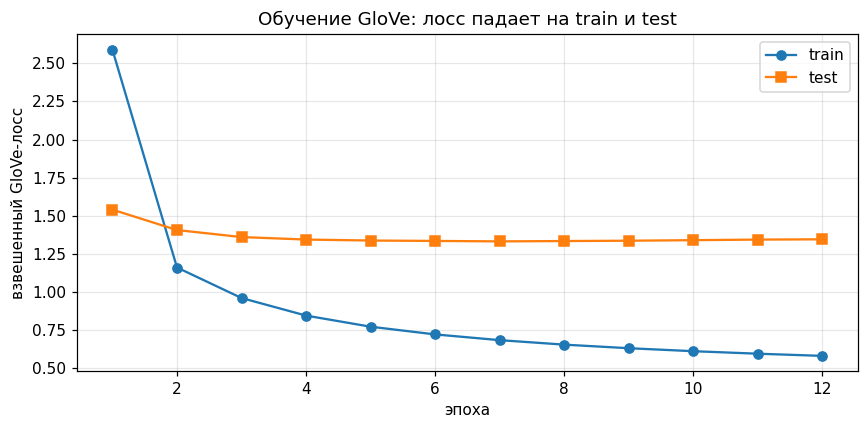

In [25]:
tr_hist = [a for a, b in loss_history]
te_hist = [b for a, b in loss_history]
plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCHS + 1), tr_hist, 'o-', label='train')
plt.plot(range(1, EPOCHS + 1), te_hist, 's-', label='test')
plt.xlabel('эпоха'); plt.ylabel('взвешенный GloVe-лосс')
plt.title('Обучение GloVe: лосс падает на train и test')
plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.show()

## 6.5. Проверяем качество GloVe

Те же тесты, что и для PPMI+SVD: соседи и аналогии. Соседи у GloVe заметно чище, чем у SVD (`king` → `charles`, `george`, `henry` вместо голых римских цифр).

**Про аналогии — честно.** На корпусе в 40 000 предложений аналогии работают слабо у *обоих* методов: чтобы направление «пол» или «страна→столица» стало линейным, нужны миллиарды слов. Это ожидаемый и поучительный результат: аналогии — свойство **больших** корпусов, а не «магии» конкретной формулы.

In [26]:
print('=== Ближайшие соседи (GloVe) ===')
for w in ['king', 'music', 'war', 'city', 'church', 'river', 'french']:
    print(f'{w:8s} ->', nearest(E_glove, w))

print()
print('=== Аналогии (GloVe) — на 40k предложений ожидаемо шумные ===')
for a, b, c in [('man', 'king', 'woman'), ('france', 'paris', 'italy')]:
    print(f'{a} : {b} === {c} : ?   ->', analogy(E_glove, a, b, c))

=== Ближайшие соседи (GloVe) ===
king     -> [('charles', 0.8), ('george', 0.78), ('henry', 0.78), ('philip', 0.72), ('ii', 0.71), ('john', 0.7)]
music    -> [('classical', 0.81), ('house', 0.78), ('sony', 0.7), ('contemporary', 0.61), ('awards', 0.61), ('industry', 0.6)]
war      -> [('post', 0.73), ('ended', 0.69), ('cold', 0.69), ('world', 0.67), ('ii', 0.66), ('during', 0.64)]
city     -> [('oklahoma', 0.79), ('mexico', 0.78), ('york', 0.78), ('new', 0.77), ('centre', 0.73), ('area', 0.73)]
church   -> [('catholic', 0.87), ('roman', 0.79), ('christian', 0.66), ('orthodox', 0.64), ('reformed', 0.59), ('anglican', 0.58)]
river    -> [('yangtze', 0.78), ('basin', 0.7), ('beyond', 0.62), ('east', 0.62), ('along', 0.62), ('region', 0.61)]
french   -> [('german', 0.72), ('revolution', 0.69), ('italian', 0.62), ('forces', 0.61), ('the', 0.61), ('british', 0.61)]

=== Аналогии (GloVe) — на 40k предложений ожидаемо шумные ===
man : king === woman : ?   -> [('edward', 0.63), ('henry', 0.62),

## 6.6. Сравнение карт PPMI+SVD и GloVe

Положим две t-SNE-проекции рядом. Обратите внимание: GloVe-кластеры обычно плотнее и «идеоматичнее» (рядом оказываются `king`/`queen`/`prince`, страны, деньги, времена года).

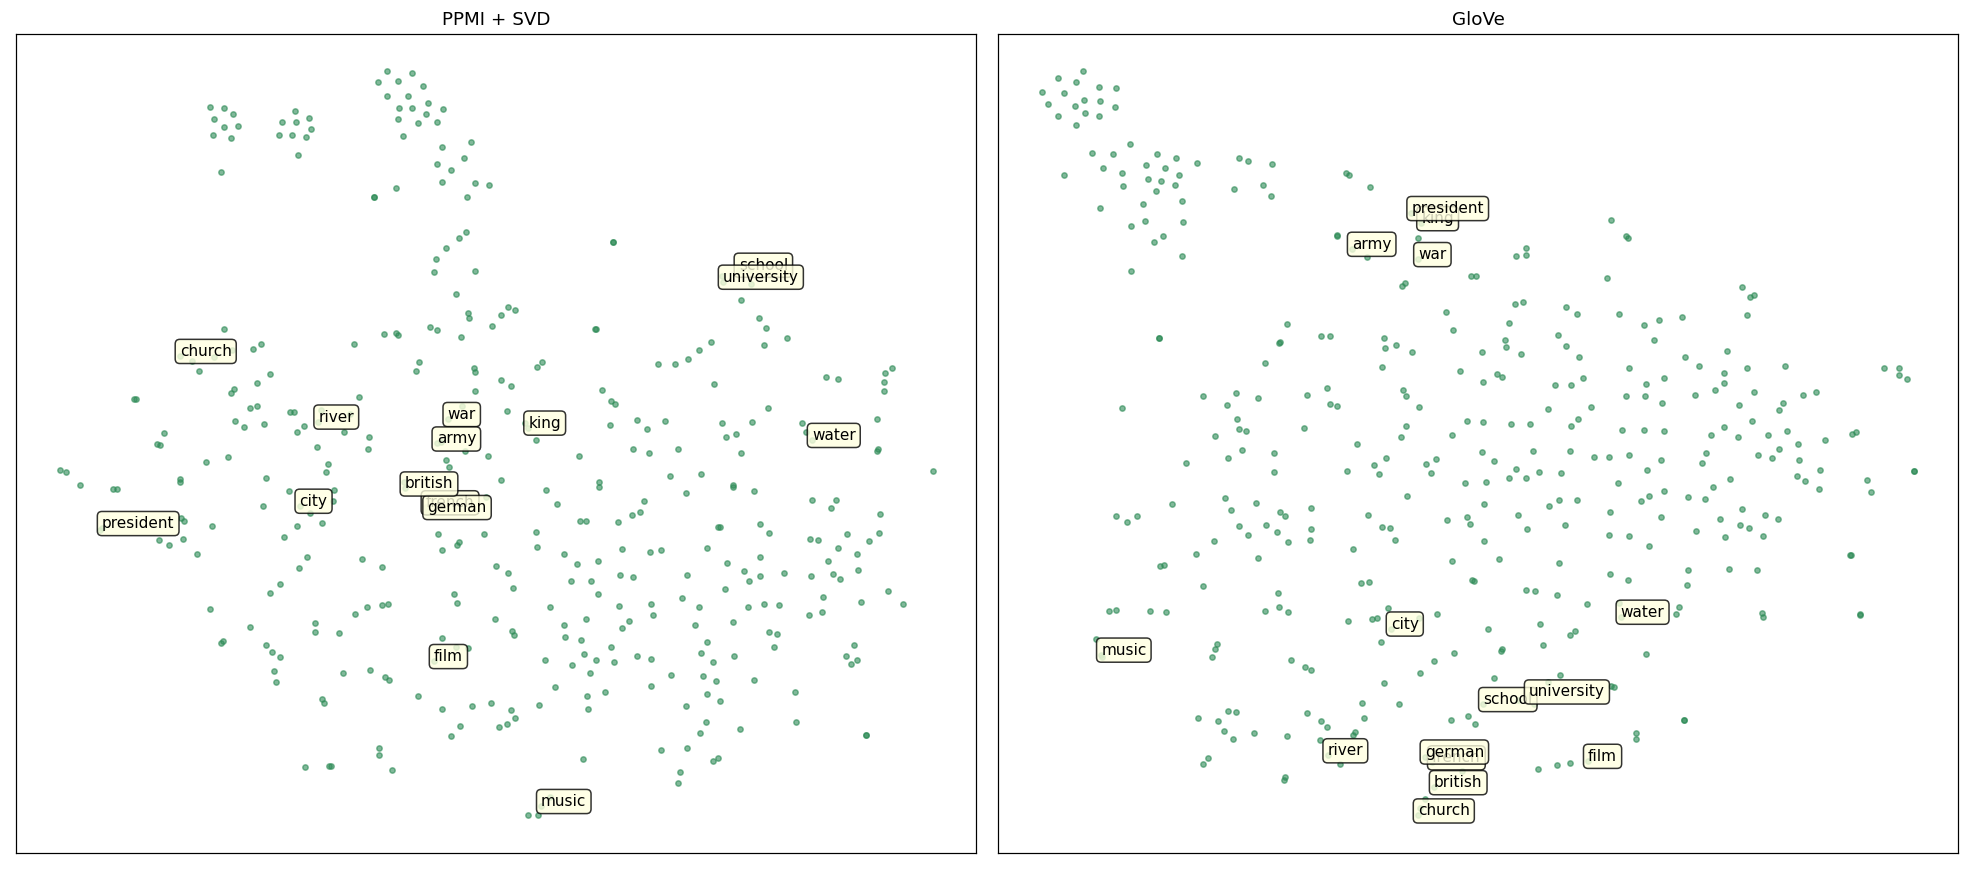

In [27]:
ts2 = TSNE(n_components=2, perplexity=25, random_state=SEED, init='pca', learning_rate='auto')
proj_glove = ts2.fit_transform(E_glove[frequent_idx])

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, proj, name in [(axes[0], proj, 'PPMI + SVD'), (axes[1], proj_glove, 'GloVe')]:
    ax.scatter(proj[:, 0], proj[:, 1], s=12, color='seagreen', alpha=0.6)
    for w in interesting:
        if w in frequent:
            j = frequent.index(w)
            ax.annotate(w, (proj[j, 0], proj[j, 1]), fontsize=10,
                        bbox=dict(boxstyle='round', fc='lightyellow', alpha=0.8))
    ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 6.7. Итог по GloVe

GloVe — «золотая середина»: глобальная статистика (как SVD) + обучение по парам (как word2vec). Один понятный лосс, устойчивое обучение, качественные линейные аналогии. Именно поэтому GloVe долго был дефолтом для переносимых эмбеддингов — до появления контекстных моделей.

---
# Часть 7. Честное сравнение: классификация текстов

## 7.1. Задача

Пора свести все методы в одну таблицу. Возьмём реальную задачу: **классификация предложений по теме**. В SQuAD у каждой статьи есть `title`; выберем 8 тем, у которых много предложений, и попросим модель угадать тему предложения.

Это классический сценарий «мало данных, много текста»: именно здесь BoW/TF-IDF традиционно сильны, а эмбеддинги надо ещё правильно применить.

Категории: `Buddhism`, `New_York_City`, `American_Idol`, `Israel`, `Portugal`, `Southampton`, `Greece`, `Middle_Ages`. По 300 предложений на класс — всего 2400.

In [28]:
CATEGORIES = ['Buddhism', 'New_York_City', 'American_Idol', 'Israel',
              'Portugal', 'Southampton', 'Greece', 'Middle_Ages']
PER_CLASS = 300

by_title = {c: [] for c in CATEGORIES}
for article in squad:
    if article['title'] in by_title:
        for p in article['paragraphs']:
            by_title[article['title']] += sent_tokenize(p['context'])

clf_docs, clf_y = [], []
rng = random.Random(SEED)
for label, c in enumerate(CATEGORIES):
    sents = by_title[c][:]
    rng.shuffle(sents)
    sents = sents[:PER_CLASS]
    clf_docs += sents
    clf_y += [label] * len(sents)
clf_y = np.array(clf_y)

print(f'всего документов: {len(clf_docs):,}, классов: {len(CATEGORIES)}')
for i, c in enumerate(CATEGORIES):
    print(f'  {i} {c:16s} {int((clf_y == i).sum())}')

всего документов: 2,400, классов: 8
  0 Buddhism         300
  1 New_York_City    300
  2 American_Idol    300
  3 Israel           300
  4 Portugal         300
  5 Southampton      300
  6 Greece           300
  7 Middle_Ages      300


## 7.2. Единый протокол оценки

Чтобы сравнение было честным, все методы оцениваем одинаково: один и тот же `train_test_split` (80/20, стратифицированный) и один и тот же классификатор поверх признаков — **логистическая регрессия** (быстрая и стабильная для разреженных и плотных признаков).

Представления, которые сравниваем:

1. **BoW** — счётчики слов (разреженно, $V$);
2. **TF-IDF** — счётчики с весами (разреженно, $V$);
3. **PPMI+SVD (mean)** — среднее эмбеддингов слов предложения ($d=100$);
4. **GloVe (mean)** — среднее эмбеддингов слов ($d=50$);
5. **FastText n-grams** — мешок слов + символьных n-грамм (разреженно, хешировано).

In [29]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import normalize

# фиксированный split для ВСЕХ методов
idx_all = np.arange(len(clf_docs))
idx_train, idx_test = train_test_split(idx_all, test_size=0.2, random_state=SEED,
                                       stratify=clf_y)

results = {}

def evaluate(name, X, verbose=True):
    '''Обучить логистическую регрессию на X и вернуть accuracy на тесте.'''
    if sp.issparse(X):
        X = X.tocsr()
    clf = LogisticRegression(max_iter=1000, C=10)
    clf.fit(X[idx_train], clf_y[idx_train])
    acc = clf.score(X[idx_test], clf_y[idx_test])
    results[name] = acc
    if verbose:
        print(f'{name:22s} accuracy = {acc:.4f}')
    return acc

print('Форма данных: train =', len(idx_train), ', test =', len(idx_test))
print()

Форма данных: train = 1920 , test = 480



### BoW и TF-IDF

Строим «с нуля», чтобы не потерять связь с частью 1–2 (внутри sklearn всё то же самое: словарь + матрица).

In [30]:
# --- BoW ---
cv = CountVectorizer(tokenizer=tokenize, lowercase=False, min_df=2, token_pattern=None)
X_clf_bow = cv.fit_transform(clf_docs)
clf_vocab = cv.get_feature_names_out()
evaluate('BoW', X_clf_bow)

# --- TF-IDF ---
tv = TfidfVectorizer(tokenizer=tokenize, lowercase=False, min_df=2,
                     sublinear_tf=True, token_pattern=None)
X_clf_tfidf = tv.fit_transform(clf_docs)
evaluate('TF-IDF', X_clf_tfidf)
print()

BoW                    accuracy = 0.8167
TF-IDF                 accuracy = 0.8750



### Эмбеддинги + усреднение

У эмбеддингов слов нет встроенного способа получить вектор предложения. Простейший (и удивительно неплохой) — **усреднить векторы слов**. Формально это «мягкий» BoW: каждое слово голосует своим вектором.

Важная деталь: усреднение теряет порядок и размывает сигнал — короткое предложение из 5 слов размывается по 50–100 измерениям. Поэтому на такой задаче эмбеддинги часто **проигрывают** TF-IDF. Это честный и поучительный результат.

In [31]:
# карта «слово классификационного словаря -> id в словаре эмбеддингов»
vocab_to_emb = {j: w2i[w] for j, w in enumerate(clf_vocab) if w in w2i}

def build_emb_features(E, X_counts, v2e):
    '''Средний эмбеддинг слов документа (по ненулевым словам).

    E: матрица эмбеддингов (V_emb, d); X_counts: разреженный BoW; v2e: карта индексов.
    '''
    out = np.zeros((X_counts.shape[0], E.shape[1]), dtype=np.float32)
    for i in range(X_counts.shape[0]):
        row = X_counts.getrow(i)
        cols = [j for j in row.indices if j in v2e]
        if cols:
            out[i] = E[[v2e[j] for j in cols]].mean(axis=0)
    return normalize(out)

X_clf_svd   = build_emb_features(E_svd,   X_clf_bow, vocab_to_emb)
X_clf_glove = build_emb_features(E_glove, X_clf_bow, vocab_to_emb)

evaluate('PPMI+SVD (mean)', X_clf_svd)
evaluate('GloVe (mean)', X_clf_glove)
print(f'\nпокрытие слов TF-IDF-словаря в словаре эмбеддингов: '
      f'{len(vocab_to_emb)} / {len(clf_vocab)} = {len(vocab_to_emb)/len(clf_vocab):.1%}')

PPMI+SVD (mean)        accuracy = 0.7750
GloVe (mean)           accuracy = 0.5542

покрытие слов TF-IDF-словаря в словаре эмбеддингов: 3209 / 4329 = 74.1%


### FastText-классификатор (мешок n-грамм)

Соберём разреженную матрицу признаков: слово + его символьные n-граммы, хешированные в фиксированное пространство. Это тот самый fastText-классификатор. Здесь n-граммы дают устойчивость к редким словам.

In [32]:
D_HASH = 2 ** 16

def build_fasttext_features(docs, D=D_HASH):
    rows, cols, vals = [], [], []
    for i, d in enumerate(docs):
        idx_, cnt_ = featurize_text(d, D=D)
        rows += [i] * len(idx_); cols += list(idx_); vals += list(cnt_)
    return csr_matrix((vals, (rows, cols)), shape=(len(docs), D), dtype=np.float32)

X_clf_ft = build_fasttext_features(clf_docs)
evaluate('FastText n-grams', X_clf_ft)
print()

FastText n-grams       accuracy = 0.8250



## 7.3. Итоговая таблица и график

Сведём результаты. Числа — accuracy на отложенной тестовой выборке.

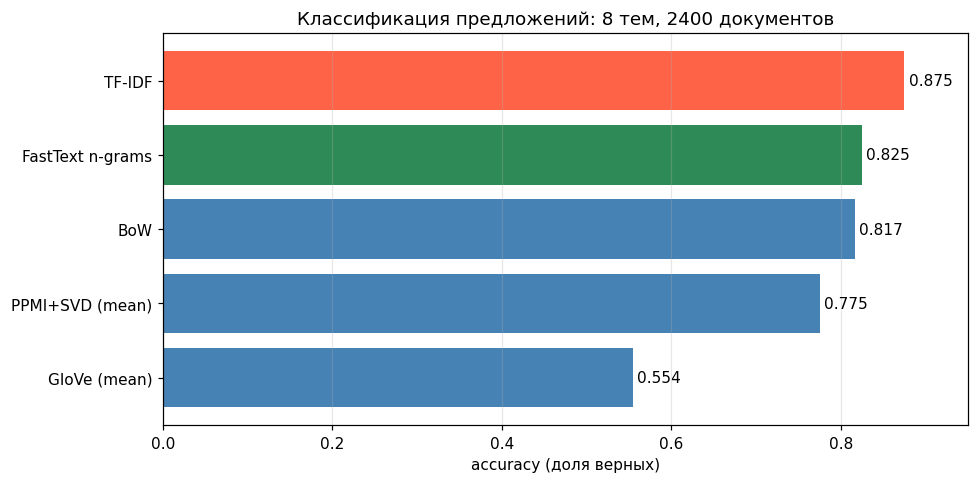

Итог:
  TF-IDF                 0.8750
  FastText n-grams       0.8250
  BoW                    0.8167
  PPMI+SVD (mean)        0.7750
  GloVe (mean)           0.5542


In [33]:
plt.figure(figsize=(9, 4.5))
order = sorted(results.items(), key=lambda kv: kv[1])
names = [k for k, _ in order]
vals = [v for _, v in order]
colors = ['tomato' if 'TF-IDF' in n else 'seagreen' if 'FastText' in n
          else 'steelblue' for n in names]
bars = plt.barh(names, vals, color=colors)
for b, v in zip(bars, vals):
    plt.text(v + 0.005, b.get_y() + b.get_height()/2, f'{v:.3f}', va='center', fontsize=10)
plt.xlim(0, 0.95); plt.xlabel('accuracy (доля верных)')
plt.title('Классификация предложений: 8 тем, 2400 документов')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout(); plt.show()

print('Итог:')
for k, v in sorted(results.items(), key=lambda kv: -kv[1]):
    print(f'  {k:22s} {v:.4f}')

## 7.4. Почему усреднение эмбеддингов проигрывает

Полезно увидеть **почему** усреднённые эмбеддинги проиграли. Возьмём одно предложение и его средний вектор: топ-слова по косинусу к среднему показывают, насколько усреднение размывает редкие, но решающие слова среди служебных. Это наглядно объясняет слабость mean-pooling.

In [34]:
# разберём один документ
doc_i = idx_test[0]
doc = clf_docs[doc_i]
actual = CATEGORIES[clf_y[doc_i]]

# средний GloVe-вектор документа и вклад отдельных слов
toks = [t for t in tokenize(doc) if t in w2i]
doc_vec = E_glove[[w2i[t] for t in toks]].mean(axis=0)
doc_vec = doc_vec / (np.linalg.norm(doc_vec) + 1e-9)

# насколько «типичны» слова документа: косинус с усреднённым вектором
sims = [float(E_glove[w2i[t]] @ doc_vec) for t in toks]
order = np.argsort(-np.array(sims))

print(f'Предложение (тема: {actual}):')
print(' ', doc[:150], '...')
print()
print('Слова, наиболее "типичные" для среднего вектора:')
print(' ', ', '.join(toks[i] for i in order[:8]))
print('Слова, наименее типичные (их усреднение "размывает"):')
print(' ', ', '.join(toks[i] for i in order[-8:]))

Предложение (тема: Southampton):
  Many of the world's largest cruise ships can regularly be seen in Southampton water, including record-breaking vessels from Royal Caribbean and Carniv ...

Слова, наиболее "типичные" для среднего вектора:
  the, and, of, in, from, including, many, water
Слова, наименее типичные (их усреднение "размывает"):
  seen, ships, southampton, caribbean, corporation, vessels, breaking, regularly


## 7.5. Выводы сравнения

| Метод | Размерность | Учёт порядка | OOV | Сильные стороны | Слабые стороны |
|---|---|---|---|---|---|
| **BoW** | $V$ (разреженно) | ✗ | ✗ | простота, скорость | частые слова доминируют |
| **TF-IDF** | $V$ (разреженно) | ✗ | ✗ | сильный бейзлайн классификации | нет синонимии/порядка |
| **PPMI+SVD** | $d$ (плотно) | ✗ (через контекст) | ✗ | дешёвые эмбеддинги, аналогии | дорогое SVD, слабый mean |
| **word2vec** | $d$ (плотно) | ✗ (через контекст) | ✗ | лучшие аналогии (окно 5–10) | один вектор на слово, нет OOV |
| **FastText** | $d$ (плотно) | ✗ (через контекст) | ✓ | морфология, опечатки, OOV | больше параметров |
| **GloVe** | $d$ (плотно) | ✗ (через контекст) | ✗ | глобальная статистика + устойчивость | один вектор на слово |

**Главные наблюдения:**

1. **На коротких предложениях TF-IDF сложно обыграть.** Это не «недоучённая» модель: разреженное представление сохраняет конкретные слова, а mean-pooling эмбеддингов размывает их. Сила эмбеддингов раскрывается на больших корпусах, переносе между задачами и работе с редкими словами.
2. **Усреднение — самый грубый способ получить вектор документа.** Настоящие модели (CNN/RNN/Transformer поверх эмбеддингов, а позже — контекстные эмбеддинги) учитывают порядок и снимают это ограничение.
3. **Метод надо выбирать под задачу.** Мало данных → BoW/TF-IDF. Много данных и морфология → FastText. Нужны универсальные векторы слов для переноса → GloVe/word2vec.
4. **Честная оговорка про GloVe (mean).** Здесь он проиграл даже PPMI+SVD (0.55 против 0.78). Это ожидаемо: статические эмбеддинги раскрываются на **больших** корпусах (миллиарды токенов), а у нас — всего 40 000 предложений. Levy и др. (2015) показали, что на малых корпусах правильно настроенный PPMI+SVD часто не хуже word2vec/GloVe. Урок: не верьте, что «нейросетевые эмбеддинги всегда лучше» — размер корпуса и способ агрегации решают не меньше, чем архитектура.

---
# Часть 8. Итоги

## 8.1. Весь путь одной таблицей

| Метод | Идея одной фразой | Размерность | Нужен корпус слов | OOV |
|---|---|---|---|---|
| **BoW** | считаем слова | $V$ (разр.) | нет | ✗ |
| **TF-IDF** | счёт × редкость | $V$ (разр.) | нет | ✗ |
| **pPMI+SVD** | считаем соседей → факторизуем | $d$ (плотно) | да | ✗ |
| **word2vec** | предсказываем контекст | $d$ (плотно) | да | ✗ |
| **FastText** | слово = сумма n-грамм | $d$ (плотно) | да | ✓ |
| **GloVe** | подгоняем скалярное произведение под log-частоту | $d$ (плотно) | да | ✗ |

## 8.2. Что выбирать на практике

* **Нужно быстро и надёжно, данных мало** → TF-IDF + линейная модель. До сих пор лучший первый бейзлайн для текста.
* **Нужны переносимые векторы слов** (для поиска, кластеризации, фич в других моделях) → GloVe или FastText (обученные на большом корпусе, например Common Crawl).
* **Много морфологии / опечатки / сленг** → FastText (n-граммы).
* **Обучаете свою нейросеть для языка** → почти всегда начинают со своих эмбеддингов (nn.Embedding), а предобученные инициализируют ими.

## 8.3. Куда двигаться дальше

Все рассмотренные векторы — **статические**: у слова один вектор, независимо от контекста. `bank` (берег) и `bank` (банк) неразличимы. Это фундаментальное ограничение, и его снимают:

* **контекстные эмбеддинги** (ELMo, BERT, GPT) — вектор слова зависит от всего предложения;
* **трансформеры** — современный стандарт, там эмбеддинги уже не цель, а один из слоёв;
* **от эмбеддингов к задачам** — классификация/generation поверх эмбеддингов (мы сделали mean-pooling; дальше — CNN/RNN/attention).

## 8.4. Мини-шпаргалка формул

$$\mathrm{tfidf}(t,d) = \underbrace{\frac{\text{count}(t,d)}{|d|}}_{\mathrm{tf}} \cdot \underbrace{\log\frac{1+N}{1+\mathrm{df}(t)}+1}_{\mathrm{idf}}$$

$$\mathrm{PMI}(w,c) = \log \frac{\#(w,c)\cdot \text{total}}{\#(w)\cdot \#(c)},\qquad \mathrm{PPMI} = \max(\mathrm{PMI}, 0)$$

$$\text{word2vec (SGNS): } \max\ \log\sigma(E_w\cdot E'_c) + \sum_{i=1}^{k}\log\sigma(-E_w\cdot E'_{c_i})$$

$$\text{GloVe: } \min \sum_{w,c} f(X_{wc})\big(E_w\cdot E'_c + b_w + b_c - \log X_{wc}\big)^2$$

## 8.5. Что попробовать самому

1. **Поиграйте с `WINDOW`** (часть 3, 6): окно 2 даст синтаксических соседей, окно 10 — тематических. Сравните соседей `king`.
2. **Поменяйте `alpha` в GloVe** (0.5, 0.75, 1.0) и посмотрите, как меняются аналогии.
3. **Разные способы пулинга**: mean, weighted-mean по idf, max-pooling. Как изменится качество классификации?
4. **Увеличьте `DIM`** эмбеддингов (50 → 200) и посмотрите на качество аналогий и на время обучения.
5. **Добавьте предобученный FastText/GloVe** (учтите: в лекции мы принципиально обучали сами) и сравните на задаче классификации.
6. **Реализуйте SGNS** (Skip-gram + negative sampling) — как в части 4, но кодом. [Это уже за рамками лекции, но отличное упражнение.]

## 8.6. Полезные внешние ресурсы

- [Efficient Estimation of Word Representations in Vector Space (Mikolov et al., 2013)](https://arxiv.org/abs/1301.3781) — оригинальный word2vec (CBOW, Skip-gram).
- [Distributed Representations of Words and Phrases and their Compositionality (Mikolov et al., 2013)](https://arxiv.org/abs/1310.4546) — negative sampling и subsampling.
- [GloVe: Global Vectors for Word Representation (Pennington et al., 2014)](https://nlp.stanford.edu/pubs/glove.pdf) — оригинальная статья GloVe.
- [Enriching Word Vectors with Subword Information (Bojanowski et al., 2017)](https://arxiv.org/abs/1607.04606) — FastText embeddings.
- [Bag of Tricks for Efficient Text Classification (Joulin et al., 2016)](https://arxiv.org/abs/1607.01759) — FastText-классификатор.
- [Improving Distributional Similarity with Lessons Learned from Word Embeddings (Levy et al., 2015)](https://www.aclweb.org/anthology/Q15-1016.pdf) — связь SGNS, PPMI и гиперпараметров.
- [Neural Word Embedding as Implicit Matrix Factorization (Levy & Goldberg, 2014)](https://papers.nips.cc/paper/2014/file/feab05aa91085b7a8012516bc3533958-Paper.pdf) — почему SGNS ≈ PPMI.

---

> **Резюме одной строкой.** Тексту нужны числа; BoW и TF-IDF дают разреженные векторы документов, а pPMI+SVD, word2vec, FastText и GloVe — плотные векторы слов, где близость по смыслу превращается в близость по косинусу.
